# Classificação de Imagens com CNN: Avaliação de Cabeças Clássicas e Bayesianas sob Diferentes Métodos de Otimização

**Gabriel de Laet Pereira**  
Universidade de São Paulo, São Carlos, Brasil  

# Classificação de Imagens com CNN: Comparação entre Cabeças Determinísticas e Bayesianas (Gradiente Natural vs. Aproximação de Laplace)

Vamos construir e avaliar uma **Rede Neural Convolucional (CNN)** para classificar imagens (gatos $\times$ cachorros) e, ao final, acoplar uma **cabeça classificadora MLP não convexa (`128 -> 32 -> 16 -> 1` com ativações ReLU) treinada de forma bayesiana via Gradiente Natural (aproximação diagonal)**, que além da classe devolve medidas calibradas de incerteza epistêmica e preditiva.

O fluxo de trabalho segue as etapas típicas de um projeto de Deep Learning com Keras/TensorFlow:

1. **Carregar e explorar os dados**: baixar e ler as imagens e visualizar alguns exemplos;
2. **Preparar os dados**: padronizar todas as imagens para a **mesma dimensão** (corte central + redimensionamento, sem distorcer), dividir em **treino / validação / teste** (70% / 15% / 15%, estratificado) e pré-processar (**imagens coloridas RGB** e normalização);
3. **Definir a arquitetura da CNN**: blocos de convolução dupla com *batch normalization*, *pooling*, aumento de dados e *dropout*;
4. **Compilar o modelo**: escolher a função de custo, o otimizador e as métricas de acompanhamento;
5. **Treinar o modelo**: ajustar os pesos aos dados de treino, monitorando a validação, com parada antecipada (*early stopping*);
6. **Avaliar o modelo**: medir o desempenho no conjunto de **teste** (usado só uma vez, no final) e inspecionar previsões individuais;
7. **Cabeça MLP bayesiana e análise geométrica**: congelar o extrator convolucional e treinar a nova arquitetura MLP não convexa em três regimes — **Determinística (Adam)**, **Bayesiana via Gradiente Natural (diagonal)** e **Bayesiana via Laplace + Newton** — comparando desempenho, calibração (ECE), custo de escala ($O(P)$ vs. $O(P^2)$), diagnóstico da Hessiana exata indefinida e detecção de incerteza em erros e em dados fora da distribuição (OOD).

> **Observação:** este notebook foi escrito para rodar no **Google Colab**. As imagens são **baixadas direto para a máquina do Colab** (muito mais rápido para treinar); o Google Drive é usado apenas para salvar e carregar os pesos do extrator convolucional (`cnn_base_cats_dogs.keras`) e a imagem ilustrativa OOD (`uno.jfif`). Se você for executá-lo em outro ambiente, ajuste a etapa de montagem do Drive e os caminhos de arquivo de acordo. Como a rede usa imagens coloridas e amostragem Monte Carlo na inferência, **ative uma GPU** (menu *Ambiente de execução → Alterar tipo de ambiente de execução*), caso contrário o treinamento fica lento.


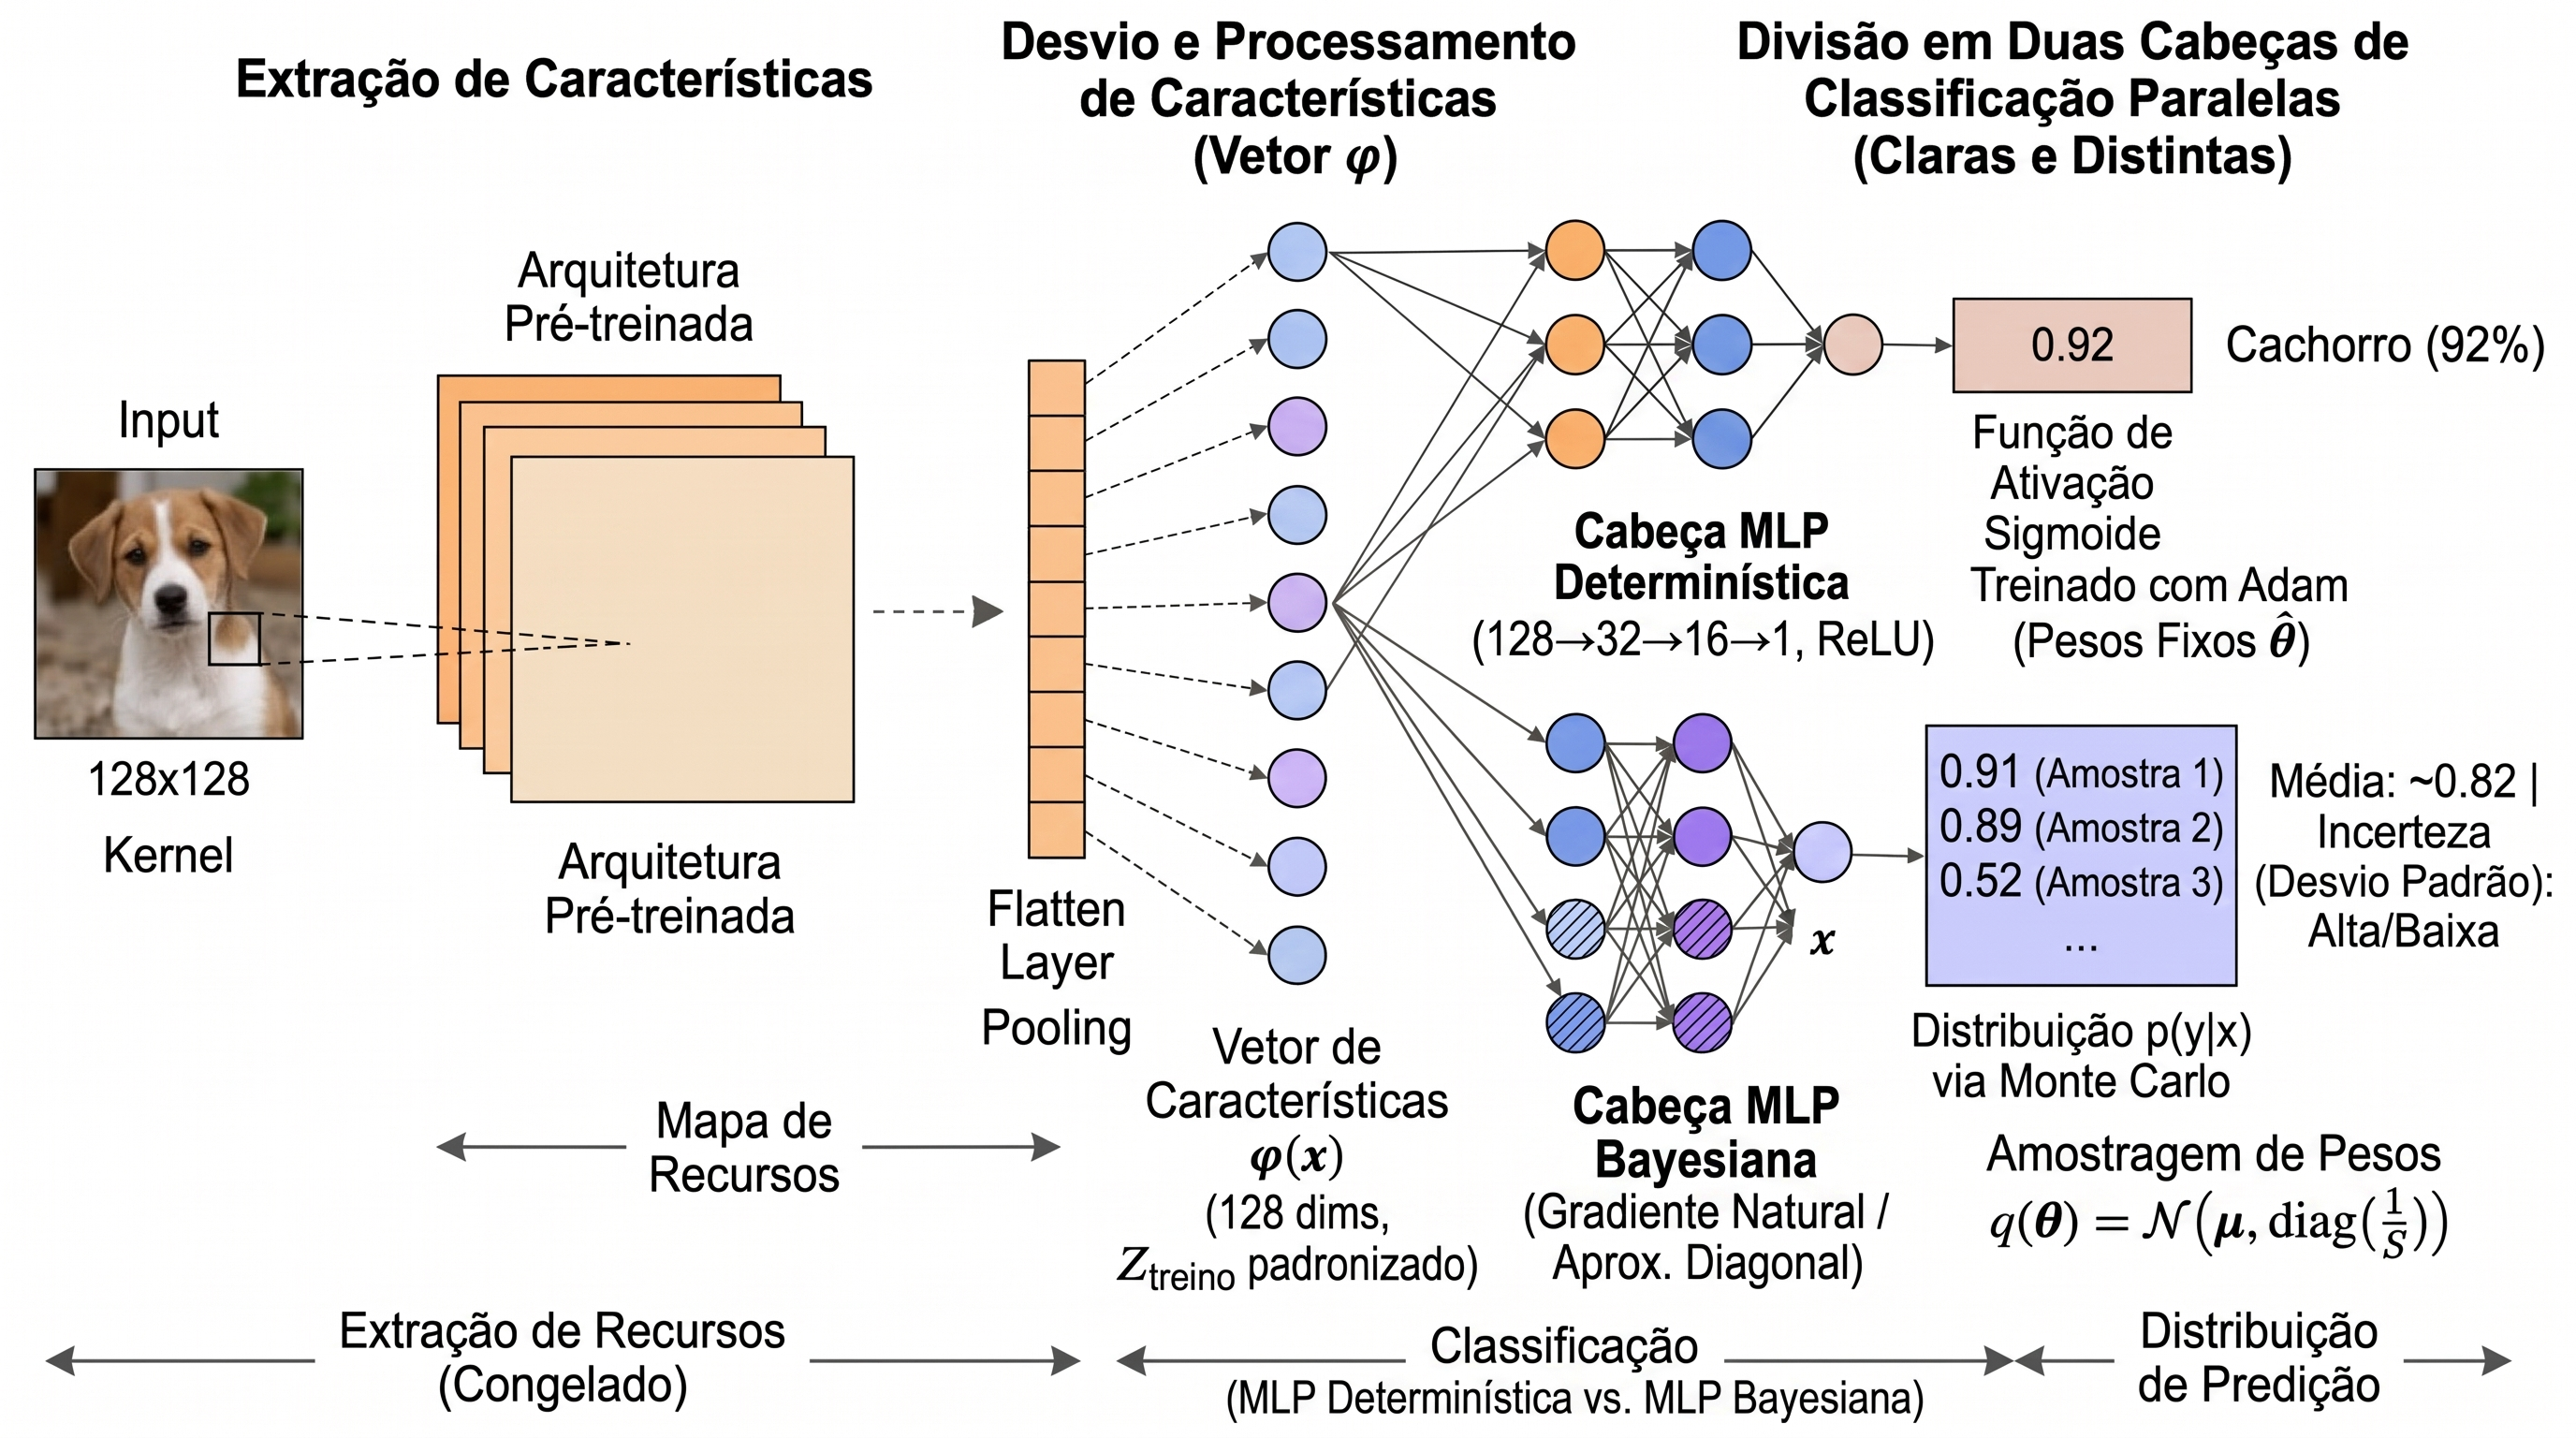

### Visão Geral da Arquitetura: Extrator Convolucional + Cabeça MLP Bayesiana

O diagrama acima ilustra o fluxo completo do modelo:
* **Extração de Características (Congelada):** Uma CNN pré-treinada na base de gatos e cachorros recebe imagens RGB ($128 \times 128$) e extrai um vetor latente de **128 dimensões** ($\varphi(x)$), padronizado apenas com a média e o desvio-padrão do conjunto de treino ($Z_{\text{treino}}$).
* **Cabeça MLP Determinística (Baseline):** Rede multicamada não convexa (`128 -> 32 -> 16 -> 1` com ativações ReLU e saída sigmoide), treinada com Adam para produzir uma estimativa pontual de probabilidade.
* **Cabeça MLP Bayesiana (Gradiente Natural):** A mesma arquitetura não convexa (`128 -> 32 -> 16 -> 1` com ReLU), onde os 4.673 parâmetros seguem uma distribuição variacional gaussiana com precisão diagonal $q(\theta) = \mathcal{N}(\mu, \text{diag}(1/S))$. Na inferência, $K$ amostras de pesos são sorteadas via Monte Carlo para estimar a probabilidade média e a incerteza preditiva/epistêmica.

### Conectando ao Google Drive (carregamento do extrator e dados OOD)

As imagens de treino, validação e teste são baixadas diretamente para o disco local da máquina virtual do Colab (`/content/data/PetImages`) para garantir leitura rápida durante o processamento.

O **Google Drive** é montado em `/content/drive` com duas finalidades principais neste experimento:
1. **Reaproveitar o extrator convolucional pré-treinado (`cnn_base_cats_dogs.keras`):** evita retreinar a CNN do zero e garante que todas as cabeças classificadoras (Determinística, Gradiente Natural e Laplace+Newton) avaliem exatamente as mesmas representações extraídas;
2. **Carregar a imagem ilustrativa fora da distribuição (`uno.jfif`):** utilizada no teste qualitativo de incerteza epistêmica ao final do notebook.

In [1]:
!mkdir -p /content/data
!wget -q https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip -O /content/data/catsdogs.zip
!unzip -q /content/data/catsdogs.zip -d /content/data
!ls /content/data/PetImages

Cat  Dog


In [2]:
caminho_drive = '/content/data/PetImages'

## Conectando ao Google Drive (apenas para salvar resultados)

Nesta versão as imagens vêm direto da internet para a máquina do Colab; o Drive é usado só para **guardar** o melhor modelo (*checkpoint*) e o modelo treinado. Montar o Drive deixa seus arquivos acessíveis como uma pasta local (em `/content/drive/...`). Ao executar a célula abaixo, o Colab vai pedir autorização para acessar sua conta do Google — basta seguir o link e confirmar.


In [3]:
from google.colab import drive

# Monta o Google Drive na pasta '/content/drive' deste ambiente do Colab.
# Depois deste comando, os arquivos do seu Drive ficam acessíveis normalmente,
# como se fossem arquivos locais dentro de '/content/drive/MyDrive/...'
drive.mount('/content/drive')

Mounted at /content/drive


## Passo 1 — Carregando o dataset (primeira leitura, para exploração)

Vamos usar `tf.keras.utils.image_dataset_from_directory`, uma função do Keras que **lê automaticamente** todas as imagens de uma pasta, infere os rótulos a partir dos **nomes das subpastas** (`labels='inferred'`) e já devolve um `tf.data.Dataset` pronto para uso.

Como o problema tem apenas duas classes (gato ou cachorro), usamos `label_mode='binary'`, que atribui o rótulo `0` para a primeira classe (em ordem alfabética) e `1` para a segunda.

**Mesma dimensão para todas as imagens:** as fotos originais têm tamanhos e proporções diferentes, mas a CNN exige entradas com o mesmo número de pixels. O argumento `image_size=(128, 128)` redimensiona tudo para 128×128; porém, se a foto original não for quadrada, isso **estica** a imagem e deforma o animal. Por isso usamos `crop_to_aspect_ratio=True`: a função primeiro **recorta o centro** da imagem na proporção desejada e só depois redimensiona, sem distorção.

Nesta primeira leitura carregamos o dataset **por inteiro** apenas para conferir os dados e visualizar exemplos; a divisão em treino/validação/teste acontece no Passo 4.

In [4]:
import tensorflow as tf

# Pasta com as imagens (baixada nas células anteriores).
caminho_drive = '/content/data/PetImages'

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 123   # fixa a aleatoriedade para os resultados serem reprodutíveis

# Carrega as imagens da pasta e monta um tf.data.Dataset (apenas para exploração).
dataset_exploracao = tf.keras.utils.image_dataset_from_directory(
    caminho_drive,
    labels='inferred',        # os rótulos são inferidos a partir do nome das subpastas
    label_mode='binary',      # binário, pois são apenas 2 classes (gato ou cachorro)
    image_size=IMAGE_SIZE,    # todas as imagens saem com 128x128 pixels
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    crop_to_aspect_ratio=True # recorta o centro na proporção certa, em vez de esticar a imagem
)

# class_names guarda os nomes das subpastas encontradas, em ordem alfabética
# -- é essa ordem que define qual classe recebe o rótulo 0 e qual recebe o rótulo 1.
class_names = dataset_exploracao.class_names
print("Classes detectadas:", class_names)

Found 25000 files belonging to 2 classes.
Classes detectadas: ['Cat', 'Dog']


## Passo 2 — Visualizando exemplos de gatos

Antes de treinar qualquer modelo, é sempre uma boa prática **olhar para os dados**. Vamos percorrer os lotes do dataset até encontrar 9 imagens rotuladas como gato e exibi-las em uma grade 3×3.

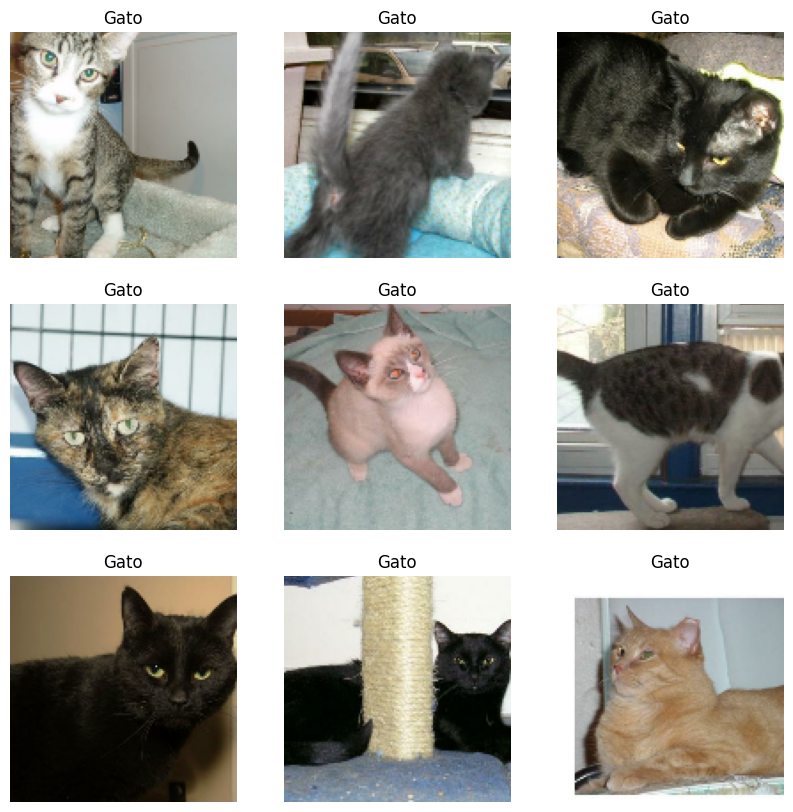

In [5]:
import matplotlib.pyplot as plt

# Descobre qual índice (0 ou 1) corresponde à classe 'cats_set',
# usando a lista de nomes de classes obtida no passo anterior.
# Como o rótulo binário segue a mesma ordem alfabética de class_names,
# esse índice é exatamente o valor do rótulo (0 ou 1) usado para "gato".
cat_class_index = class_names.index('Cat')

plt.figure(figsize=(10, 10))
num_gatos_exibidos = 0
max_gatos_exibir = 9  # queremos mostrar até 9 imagens de gatos

# Percorre os lotes (batches) do dataset...
for images, labels in dataset_exploracao:
    # ...e, dentro de cada lote, percorre as imagens individualmente.
    for i in range(len(images)):
        if labels[i] == cat_class_index:  # esta imagem é de um gato?
            ax = plt.subplot(3, 3, num_gatos_exibidos + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title("Gato")
            plt.axis("off")
            num_gatos_exibidos += 1
            if num_gatos_exibidos >= max_gatos_exibir:
                break
    if num_gatos_exibidos >= max_gatos_exibir:
        break  # já achamos 9 gatos, não precisa continuar procurando

plt.show()

## Passo 3 — Visualizando exemplos de cachorros

O mesmo procedimento do passo anterior, agora filtrando pela classe "cachorro" — assim conseguimos conferir visualmente as duas classes do problema antes de seguir adiante.

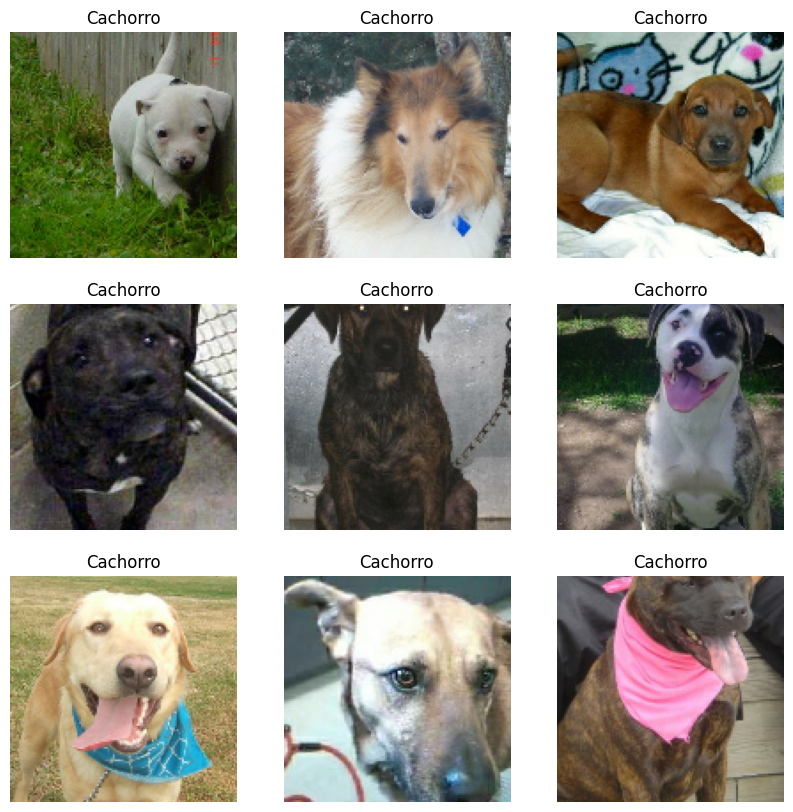

In [6]:
import matplotlib.pyplot as plt

# Descobre qual índice (0 ou 1) corresponde à classe 'dogs_set'.
dog_class_index = class_names.index('Dog')

plt.figure(figsize=(10, 10))
num_cachorros_exibidos = 0
max_cachorros_exibir = 9  # queremos mostrar até 9 imagens de cachorros

for images, labels in dataset_exploracao:
    for i in range(len(images)):
        if labels[i] == dog_class_index:  # esta imagem é de um cachorro?
            ax = plt.subplot(3, 3, num_cachorros_exibidos + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title("Cachorro")
            plt.axis("off")
            num_cachorros_exibidos += 1
            if num_cachorros_exibidos >= max_cachorros_exibir:
                break
    if num_cachorros_exibidos >= max_cachorros_exibir:
        break  # já achamos 9 cachorros, não precisa continuar procurando

plt.show()

## Passo 4 — Padronizando o tamanho e dividindo em treino, validação e teste

Agora preparamos os dados "de verdade". São duas decisões importantes:

**1. Três conjuntos, não dois.** Dividimos as imagens em:

- **treino (70%)**: usado para ajustar os pesos da rede;
- **validação (15%)**: usado durante o treino para acompanhar a generalização, ajustar hiperparâmetros e decidir a parada antecipada;
- **teste (15%)**: **só é usado no final**, uma única vez, para estimar o desempenho em imagens realmente novas.

Se usássemos o mesmo conjunto para validar *e* para a nota final (como na versão original), a acurácia final ficaria otimista, pois o conjunto já teria influenciado decisões do treinamento. A divisão é **estratificada** (`stratify`), ou seja, mantém a proporção de gatos e cachorros nos três conjuntos, e usa uma `seed` fixa para ser reprodutível.

**2. Mesmo número de pixels em todas as imagens.** Como agora montamos o `tf.data.Dataset` a partir da lista de arquivos, fazemos a padronização de forma explícita na função `carregar_imagem`: (i) decodificamos a imagem sempre com 3 canais (RGB); (ii) recortamos o centro na proporção do tamanho-alvo; (iii) redimensionamos com `tf.image.resize` para 128×128. Assim todo lote tem formato `(32, 128, 128, 3)`. As imagens são guardadas como `uint8` (0–255) no cache para economizar memória; a normalização vem no próximo passo.

In [7]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Caminho atualizado para os dados baixados no ambiente do Google Colab
caminho_imagens = '/content/data/PetImages'

# Garante que class_names exista caso a célula de exploração anterior não tenha sido rodada
if 'class_names' not in locals():
    class_names = sorted([d for d in os.listdir(caminho_imagens) if os.path.isdir(os.path.join(caminho_imagens, d))])

# ---------- 1) Lista os arquivos válidos e seus rótulos (0 = Cat, 1 = Dog) ----------
EXTENSOES = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
caminhos, rotulos = [], []
ignorados = 0

for indice, nome_classe in enumerate(class_names):
    pasta = os.path.join(caminho_imagens, nome_classe)
    for nome_arquivo in sorted(os.listdir(pasta)):
        if nome_arquivo.lower().endswith(EXTENSOES):
            caminho_completo = os.path.join(pasta, nome_arquivo)

            # Ignora arquivos vazios (0 bytes) ou sem cabeçalho JPEG/JFIF válido
            if os.path.getsize(caminho_completo) == 0:
                ignorados += 1
                continue
            with open(caminho_completo, 'rb') as f:
                cabecalho = f.read(10)
            if b'JFIF' not in cabecalho and b'Exif' not in cabecalho and not nome_arquivo.lower().endswith('.png'):
                ignorados += 1
                continue

            caminhos.append(caminho_completo)
            rotulos.append(indice)

caminhos = np.array(caminhos)
rotulos = np.array(rotulos, dtype='float32')
print(f"Total de imagens válidas encontradas: {len(caminhos)} (ignoradas/corrompidas: {ignorados})")

# ---------- 2) Divisão estratificada: 70% treino, 15% validação, 15% teste ----------
FRACAO_TESTE = 0.15
FRACAO_VAL = 0.15

c_trval, c_teste, r_trval, r_teste = train_test_split(
    caminhos, rotulos, test_size=FRACAO_TESTE, stratify=rotulos, random_state=SEED)
c_treino, c_val, r_treino, r_val = train_test_split(
    c_trval, r_trval, test_size=FRACAO_VAL / (1 - FRACAO_TESTE), stratify=r_trval, random_state=SEED)

print(f"Treino: {len(c_treino)} | Validação: {len(c_val)} | Teste: {len(c_teste)}")

# ---------- 3) Padronização do tamanho: recorte central + redimensionamento ----------
def redimensionar_com_corte(imagem, tamanho):
    # Recorta o centro da imagem na proporção do tamanho-alvo e redimensiona (sem distorcer).
    alt_alvo, larg_alvo = tamanho
    forma = tf.shape(imagem)
    alt, larg = forma[0], forma[1]
    # maior recorte central com a mesma proporção (largura/altura) da imagem-alvo
    alt_corte = tf.minimum(alt, (larg * alt_alvo) // larg_alvo)
    larg_corte = tf.minimum(larg, (alt * larg_alvo) // alt_alvo)
    desloc_alt = (alt - alt_corte) // 2
    desloc_larg = (larg - larg_corte) // 2
    imagem = tf.image.crop_to_bounding_box(imagem, desloc_alt, desloc_larg, alt_corte, larg_corte)
    return tf.image.resize(imagem, tamanho, method='bilinear')

def carregar_imagem(caminho, rotulo):
    conteudo = tf.io.read_file(caminho)
    # channels=3 garante RGB (converte imagens em tons de cinza ou com transparência)
    imagem = tf.io.decode_image(conteudo, channels=3, expand_animations=False)
    imagem = redimensionar_com_corte(imagem, IMAGE_SIZE)
    imagem = tf.cast(tf.round(imagem), tf.uint8)
    imagem.set_shape(IMAGE_SIZE + (3,))
    return imagem, rotulo

# ---------- 4) Monta os tf.data.Dataset ----------
def montar_dataset(lista_caminhos, lista_rotulos, embaralhar=False):
    ds = tf.data.Dataset.from_tensor_slices((lista_caminhos, lista_rotulos.reshape(-1, 1)))
    ds = ds.map(carregar_imagem, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()   # as imagens (já redimensionadas) ficam na memória depois da 1ª leitura
    if embaralhar:    # apenas o treino é embaralhado a cada época
        ds = ds.shuffle(len(lista_caminhos), seed=SEED)
    return ds.batch(BATCH_SIZE)

dataset_treino = montar_dataset(c_treino, r_treino, embaralhar=True)
dataset_val = montar_dataset(c_val, r_val)
dataset_teste = montar_dataset(c_teste, r_teste)

for imagens, rots in dataset_treino.take(1):
    print("Formato de um lote de imagens:", imagens.shape, "| tipo:", imagens.dtype)
    print("Formato dos rótulos:", rots.shape)

Total de imagens válidas encontradas: 24734 (ignoradas/corrompidas: 266)
Treino: 17313 | Validação: 3710 | Teste: 3711
Formato de um lote de imagens: (32, 128, 128, 3) | tipo: <dtype: 'uint8'>
Formato dos rótulos: (32, 1)


## Passo 5 — Pré-processando as imagens

Mantemos as imagens **coloridas (RGB, 3 canais)**: a cor (pelagem, olhos, fundo) traz informação extra que ajuda a separar gatos de cachorros, e o custo adicional é pequeno (só a primeira camada convolucional passa a ter 3 canais de entrada em vez de 1). Resta uma transformação:

- **Normalização dos pixels**: os valores originais vão de 0 a 255. Dividindo por 255, todos passam para o intervalo $[0, 1]$. Redes neurais treinam de forma mais estável e rápida quando as entradas estão em uma escala pequena e padronizada.

Aplicamos essa função a cada imagem do dataset com `.map(...)`, que percorre o `tf.data.Dataset` transformando cada par (imagem, rótulo) sob demanda.

In [8]:
import tensorflow as tf

def preprocessar_imagem(imagem, rotulo):
    # Normaliza os valores de pixel, originalmente em [0, 255], para o intervalo [0, 1]
    imagem = tf.cast(imagem, tf.float32) / 255.0
    return imagem, rotulo

AUTOTUNE = tf.data.AUTOTUNE
dataset_treino_processed = dataset_treino.map(preprocessar_imagem, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
dataset_val_processed = dataset_val.map(preprocessar_imagem, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
dataset_teste_processed = dataset_teste.map(preprocessar_imagem, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Conferindo o formato e a faixa de valores de um lote já processado
for image_batch, label_batch in dataset_treino_processed.take(1):
    print("Formato de um lote de imagens processadas:", image_batch.shape)
    print("Valor mínimo de pixel no lote:", tf.reduce_min(image_batch).numpy())
    print("Valor máximo de pixel no lote:", tf.reduce_max(image_batch).numpy())

Formato de um lote de imagens processadas: (32, 128, 128, 3)
Valor mínimo de pixel no lote: 0.0
Valor máximo de pixel no lote: 1.0


## Passo 6 — Conferindo visualmente o resultado do pré-processamento

Vamos exibir algumas imagens **já processadas** (coloridas e padronizadas) para confirmar visualmente que a transformação do Passo 5 funcionou como esperado, antes de seguirmos para a construção do modelo.

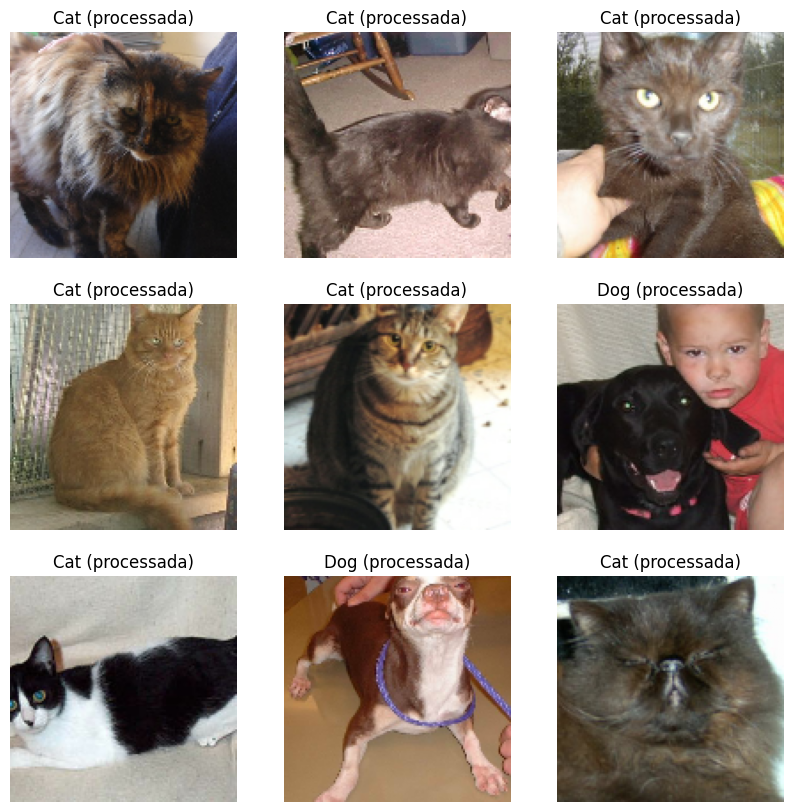

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# Pega um único lote (batch) do dataset de treino já processado
for images, labels in dataset_treino_processed.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())   # imagem RGB com valores em [0, 1]
        plt.title(f"{class_names[int(labels[i, 0])]} (processada)")
        plt.axis("off")
plt.show()

## 1. Definindo o Modelo CNN

Partimos da CNN clássica (blocos de convolução + max pooling, com 32 → 64 → 128 filtros) e a melhoramos nos pontos em que ela costuma falhar quando há poucas imagens:

- **Duas convoluções `Conv2D(n, (3, 3))` por bloco** (estilo VGG): duas convoluções 3×3 seguidas enxergam uma região maior e extraem padrões mais ricos antes de o *pooling* reduzir a imagem;
- **`padding='same'`**: preserva a altura e a largura na convolução, evitando perder as bordas da imagem a cada camada;
- **`BatchNormalization`**: normaliza as ativações dentro da rede, estabilizando e acelerando o treino (na versão original a rede demorava a sair de ~50% de acurácia). Como a normalização já recentra os valores, as convoluções ficam sem viés (`use_bias=False`);
- **`MaxPooling2D((2, 2))`**: reduz pela metade a altura e a largura, mantendo o valor máximo de cada região 2×2 (a função `construir_modelo` aceita `pooling='avg'` para usar `AveragePooling2D`);
- **Aumento de dados (*data augmentation*)**: inversões horizontais, pequenas rotações e zooms aleatórios geram variações das imagens de treino a cada época. Essas camadas só atuam no treino; na validação e no teste ficam desligadas;
- **`GlobalAveragePooling2D` no lugar de `Flatten` + `Dense(128)`**: em vez de achatar o volume 3D em um vetor enorme (que concentrava a maior parte dos parâmetros e favorecia o *overfitting*), tiramos a média de cada mapa de características, obtendo **128 atributos** por imagem;
- **`Dropout(0.5)`**: desliga aleatoriamente metade desses atributos durante o treino, como regularização;
- **`Dense(1, activation='sigmoid')`**: o neurônio de saída, para **classificação binária** — a saída é a probabilidade de a imagem ser da classe 1 (cachorro).

Construímos também um segundo modelo, `extrator`, que compartilha os mesmos pesos mas termina nos 128 atributos. Ele será usado na Seção 6 para alimentar a camada bayesiana.

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(SEED)   # reprodutibilidade (pesos iniciais, dropout, aumento de dados)

def bloco_conv(x, filtros, pooling='max'):
    # Dois blocos [Conv 3x3 -> BatchNorm -> ReLU] seguidos de um pooling 2x2.
    for _ in range(2):
        x = layers.Conv2D(filtros, (3, 3), padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    if pooling == 'max':
        return layers.MaxPooling2D((2, 2))(x)
    return layers.AveragePooling2D((2, 2))(x)

def construir_modelo(input_shape, pooling='max', dropout=0.5):
    # Aumento de dados: só é aplicado durante o treino
    data_augmentation = models.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name='data_augmentation')

    entrada = layers.Input(shape=input_shape)
    x = data_augmentation(entrada)
    for filtros in (32, 64, 128):
        x = bloco_conv(x, filtros, pooling)

    atributos = layers.GlobalAveragePooling2D(name='atributos')(x)   # 128 atributos por imagem
    x = layers.Dropout(dropout)(atributos)
    saida = layers.Dense(1, activation='sigmoid', name='saida')(x)   # probabilidade de ser cachorro

    modelo = models.Model(entrada, saida, name='cnn_gatos_cachorros')
    extrator = models.Model(entrada, atributos, name='extrator_de_atributos')   # mesmos pesos, sem a saída
    return modelo, extrator

# Imagens coloridas: 3 canais (RGB)
model, extrator = construir_modelo(IMAGE_SIZE + (3,))

# Exibe um resumo da arquitetura: cada camada, o formato da saída e o número de parâmetros
model.summary()

Model: "cnn_gatos_cachorros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 128)    │             

 Total params: 288,481 (1.10 MB)

 Trainable params: 287,585 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

## 2. Compilando o Modelo

Antes de treinar, **compilamos** o modelo, definindo três peças essenciais:

- **`optimizer='adam'`**: o algoritmo que ajusta os pesos da rede a cada passo de treinamento, com base nos gradientes calculados por retropropagação. O Adam é a escolha padrão mais robusta na maioria dos problemas, por ajustar automaticamente a taxa de aprendizado de cada peso;
- **`loss='binary_crossentropy'`**: a função de custo que o treinamento tenta minimizar — a entropia cruzada binária é a escolha padrão para problemas de classificação com exatamente duas classes, combinando bem com a ativação sigmoide da camada de saída;
- **`metrics=['accuracy']`**: métricas adicionais, calculadas a cada época apenas para **acompanhamento** (não são usadas para ajustar os pesos) — aqui, a acurácia (proporção de classificações corretas).

In [ ]:
# Compila o modelo, definindo o otimizador, a função de custo e as métricas de acompanhamento
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 3. Treinando o Modelo

Com o modelo definido e compilado, chamamos `model.fit(...)`. Passamos:

- `dataset_treino_processed`: o conjunto de treino, usado para ajustar os pesos;
- `epochs=EPOCHS`: o número **máximo** de épocas (passagens completas pelo conjunto de treino);
- `validation_data=dataset_val_processed`: o conjunto de **validação**, avaliado ao final de cada época para acompanharmos se o modelo está generalizando ou apenas decorando o treino (o conjunto de teste fica de fora até a Seção 4);
- `callbacks=[early_stop]`: a **parada antecipada** (*early stopping*) monitora a perda de validação e interrompe o treino quando ela deixa de melhorar por 7 épocas seguidas, restaurando os pesos da melhor época. Com isso podemos pedir bastante épocas sem nos preocupar com *overfitting*.

O retorno de `.fit(...)` é armazenado em `history`, que guarda a perda e a acurácia de cada época (treino e validação), usados na próxima seção.

> **Reaproveitando um treino anterior:** se o modelo já estiver salvo no Google Drive (`cnn_base_cats_dogs.keras`), a célula abaixo **carrega** a CNN e **não treina de novo**. Para forçar um novo treino, defina `RETREINAR = True`. Ao carregar, confira na Seção 4 se perda e acurácia de validação/teste batem com as do treino original: isso confirma que a divisão de dados é a mesma.


In [11]:
import os, json

CAMINHO_MODELO = '/content/drive/MyDrive/cnn_base_cats_dogs.keras'     # modelo final salvo (pesos da melhor época)
CAMINHO_HISTORICO = '/content/drive/MyDrive/history_cnn_base.json'
RETREINAR = False   # mude para True para treinar a CNN de novo, mesmo que já exista no Drive

if os.path.exists(CAMINHO_MODELO) and not RETREINAR:
    # ---- reaproveita a CNN já treinada: NÃO treina de novo ----
    model = tf.keras.models.load_model(CAMINHO_MODELO)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    # O extrator criado na Seção 1 aponta para o modelo antigo (sem treino): refazemos a partir do modelo carregado
    extrator = tf.keras.Model(model.input, model.get_layer('atributos').output, name='extrator_de_atributos')
    historico = json.load(open(CAMINHO_HISTORICO)) if os.path.exists(CAMINHO_HISTORICO) else None
    treinou_agora = False
    print("CNN carregada do Drive (sem retreinar):", CAMINHO_MODELO)
else:
    # ---- treina a CNN (só acontece se o arquivo não existir ou se RETREINAR = True) ----
    EPOCHS = 40  # número máximo de épocas; o early stopping costuma parar antes disso

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',          # acompanha a perda no conjunto de validação
        patience=7,                  # tolera 7 épocas sem melhora
        restore_best_weights=True    # no fim, volta aos pesos da melhor época
    )

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath='/content/drive/MyDrive/melhor_modelo_cats_dogs.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )

    history = model.fit(
        dataset_treino_processed,
        epochs=EPOCHS,
        validation_data=dataset_val_processed,
        callbacks=[early_stop, checkpoint]
    )
    historico = history.history
    treinou_agora = True

CNN carregada do Drive (sem retreinar): /content/drive/MyDrive/cnn_base_cats_dogs.keras


In [12]:
# Salva o modelo convolucional completo e o histórico no Google Drive (só se acabou de treinar)
if treinou_agora:
    model.save(CAMINHO_MODELO)
    with open(CAMINHO_HISTORICO, 'w') as f:
        json.dump(historico, f)
    print("Backbone convolucional e histórico salvos com sucesso no Google Drive!")
else:
    print("Modelo carregado do Drive: não há nada novo para salvar.")

Modelo carregado do Drive: não há nada novo para salvar.


### 3.1. Visualizando a curva de aprendizado

Antes de avaliar o modelo no conjunto de teste, vale a pena olhar para a **curva de aprendizado**: a perda (*loss*) e a acurácia de treino e de validação, época a época, guardadas em `history.history`. Esse é um dos gráficos mais importantes de todo o processo — é ele que revela se o treinamento está de fato convergindo, e se há sinais de **overfitting** (quando a perda de treino continua caindo, mas a de validação estabiliza ou volta a subir).

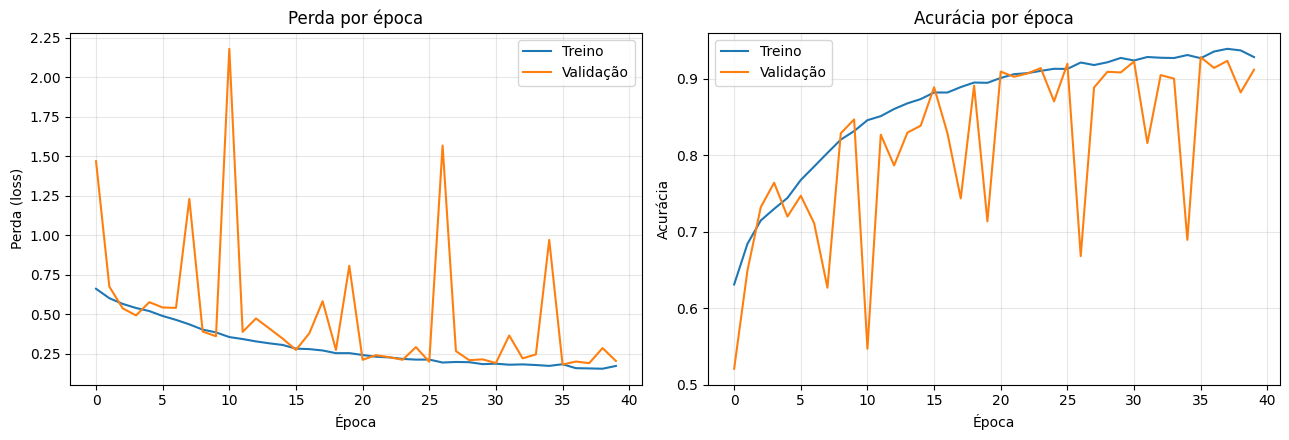

In [13]:
if historico is None:
    print('Histórico não encontrado no Drive: pule o gráfico (o modelo carregado continua válido).')
else:
    import matplotlib.pyplot as plt

    fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(13, 4.5))

    # Perda (loss) de treino e de validação por época
    eixo1.plot(historico['loss'], label='Treino')
    eixo1.plot(historico['val_loss'], label='Validação')
    eixo1.set_xlabel('Época')
    eixo1.set_ylabel('Perda (loss)')
    eixo1.set_title('Perda por época')
    eixo1.legend()
    eixo1.grid(alpha=0.3)

    # Acurácia de treino e de validação por época
    eixo2.plot(historico['accuracy'], label='Treino')
    eixo2.plot(historico['val_accuracy'], label='Validação')
    eixo2.set_xlabel('Época')
    eixo2.set_ylabel('Acurácia')
    eixo2.set_title('Acurácia por época')
    eixo2.legend()
    eixo2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Se a curva de perda de validação começar a subir enquanto a de treino continua caindo, isso é um sinal claro de sobreajuste — nesse caso, vale considerar técnicas como parada antecipada (*early stopping*), regularização, *dropout*, ou aumento de dados (*data augmentation*), especialmente relevantes quando o conjunto de treino é pequeno, como costuma ser o caso em experimentos com poucas centenas ou milhares de imagens.

## 4. Avaliando o Modelo

Agora sim usamos o **conjunto de teste**, que a rede nunca viu e que não participou de nenhuma decisão do treinamento (nem da parada antecipada). `model.evaluate(...)` devolve a perda e a acurácia calculadas sobre **todo** o conjunto de teste. Mostramos a validação ao lado só para comparação.

In [14]:
loss_val, accuracy_val = model.evaluate(dataset_val_processed, verbose=0)
loss_teste, accuracy_teste = model.evaluate(dataset_teste_processed, verbose=0)

print(f"Validação -> perda: {loss_val:.4f} | acurácia: {accuracy_val:.4f}")
print(f"Teste     -> perda: {loss_teste:.4f} | acurácia: {accuracy_teste:.4f}")

Validação -> perda: 0.1821 | acurácia: 0.9280
Teste     -> perda: 0.1820 | acurácia: 0.9267


## 5. Visualizando algumas previsões

Números agregados (perda e acurácia) resumem o desempenho geral, mas é sempre esclarecedor **olhar caso a caso**: vamos pegar um lote do conjunto de teste, gerar as previsões do modelo para essas imagens, e exibir cada imagem lado a lado com o rótulo verdadeiro e o rótulo previsto — isso ajuda a entender melhor que tipo de imagem o modelo tende a acertar ou errar.

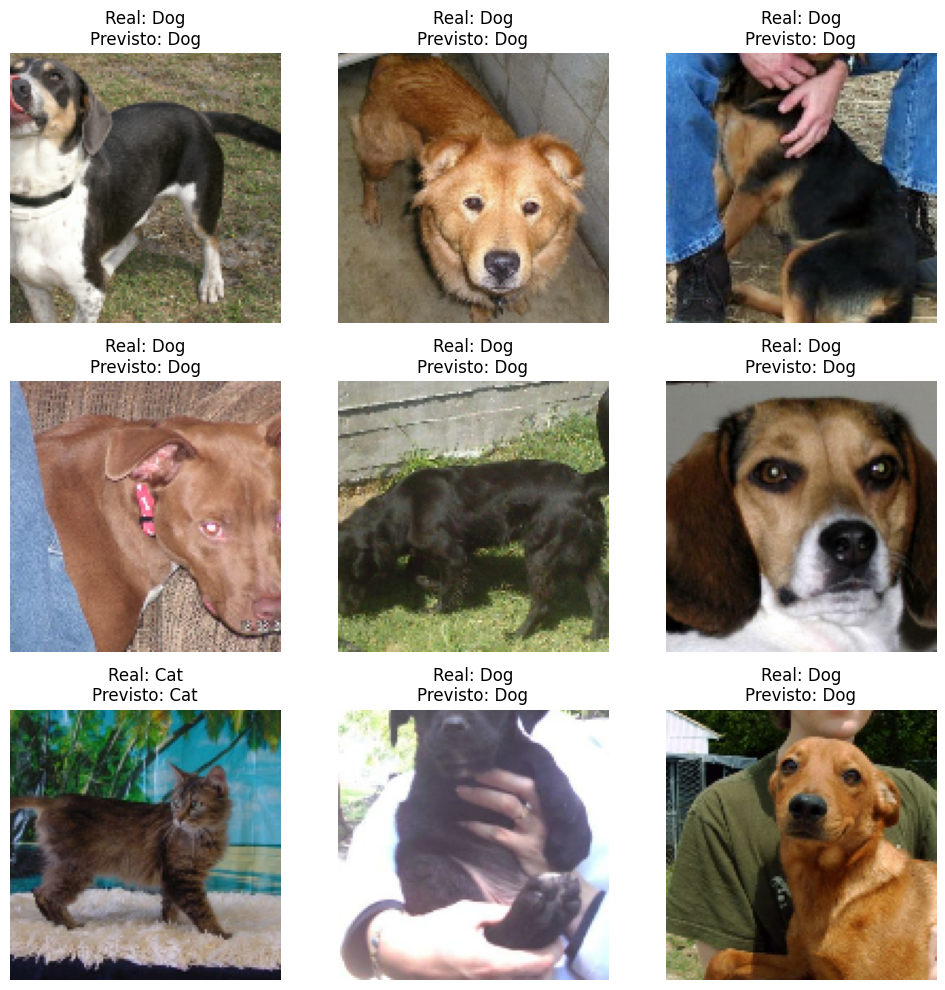

In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# Pega um único lote (batch) do conjunto de teste já processado
for images, true_labels in dataset_teste_processed.take(1):
    # Gera as previsões do modelo para esse lote de imagens
    predictions = model.predict(images, verbose=0)

    for i in range(min(len(images), 9)):  # exibe até 9 imagens
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())     # imagem RGB com valores em [0, 1]

        # Nome da classe verdadeira (rótulo real da imagem)
        true_class_name = class_names[int(true_labels[i, 0])]

        # A saída da sigmoide é um número entre 0 e 1: se for > 0.5, o modelo prevê a classe 1
        # (cachorro, seguindo a ordem alfabética de class_names); caso contrário, prevê a classe 0 (gato).
        predicted_label = int(predictions[i, 0] > 0.5)
        predicted_class_name = class_names[predicted_label]

        plt.title(f"Real: {true_class_name}\nPrevisto: {predicted_class_name}")
        plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Cabeça MLP não convexa e inferência bayesiana com gradiente natural

Até aqui, o extrator convolucional gerou representações de 128 dimensões ($\boldsymbol\phi$) e a classificação final usava pesos determinísticos fixos. Nesta seção, acoplamos uma **cabeça classificadora MLP não convexa** (`128 -> 32 -> 16 -> 1` com ativações **ReLU** e saída sigmoide, totalizando $P = 4.673$ parâmetros $\boldsymbol\theta$) e aprendemos uma **distribuição variacional** sobre esses pesos. Assim, cada previsão passa a vir acompanhada de **incerteza epistêmica** (o quanto o modelo "não sabe" em regiões pouco cobertas pelos dados).

**Estratégia em duas etapas.** Reaproveitamos o extrator convolucional pré-treinado, que permanece **congelado**: ele transforma cada imagem em um vetor padronizado de 128 atributos ($Z_{\text{treino}}, Z_{\text{val}}, Z_{\text{teste}}$), e sobre esses atributos ajustamos a cabeça MLP.

**Modelo probabilístico.**

* **Verossimilhança:** $y \mid \mathbf{x} \sim \text{Bernoulli}\big(\sigma(f_{\boldsymbol\theta}(\boldsymbol\phi))\big)$, onde $f_{\boldsymbol\theta}$ é a rede MLP com duas camadas ocultas ReLU;
* **Prior:** $p(\boldsymbol\theta) = \mathcal{N}\big(\mathbf{0},\, \delta^{-1} I\big)$, com precisão $\delta$ ajustada na validação;
* **Posterior aproximada (inferência variacional *mean-field*):** $q(\boldsymbol\theta) = \mathcal{N}\big(\boldsymbol\mu,\, \text{diag}(\mathbf{S}^{-1})\big)$, em que $\mathbf{S} \in \mathbb{R}^P$ é o vetor diagonal de precisão.

**Gradiente natural escalável (VOGN / Regra de Aprendizado Bayesiana).** O gradiente comum trata $(\boldsymbol\mu, \mathbf{S})$ como se vivessem num espaço euclidiano. O **gradiente natural** mede a distância entre distribuições pela informação de Fisher de $q$, escalonando o passo pela curvatura local: direções bem determinadas pela posterior dão passos curtos e direções incertas dão passos maiores. Para uma gaussiana diagonal, a atualização em minibatches segue:

$$\mathbf{S} \leftarrow (1-\beta)\, \mathbf{S} + \beta \left( N\, \text{diag}(\hat{H}_{\text{GGN}}) + \delta \mathbf{1} \right), \qquad \boldsymbol\mu \leftarrow \boldsymbol\mu - \alpha\, \frac{N \hat{\mathbf g} + \delta\, \boldsymbol\mu}{\mathbf{S}}$$

Em cada minibatch: sorteamos $\boldsymbol\theta \sim q$; $\hat{\mathbf g}$ é o gradiente médio da entropia cruzada; $\text{diag}(\hat{H}_{\text{GGN}})$ é a diagonal da matriz de Gauss-Newton média ($\overline{p(1-p)\,(\nabla_{\boldsymbol\theta} z)^2}$); $N$ é o total de imagens de treino e $(\alpha, \beta)$ são os tamanhos de passo.

**Quatro escolhas práticas para o regime não convexo:**

1. **Aproximação diagonal da precisão ($O(P)$ vs. $O(P^2)$):** Com $P = 4.673$ parâmetros (e muito mais em redes profundas), armazenar e fatorar uma matriz densa $P \times P$ custa memória quadrática e tempo cúbico $O(P^3)$. A precisão diagonal mantém o custo linear $O(P)$ (~19 KB) e garante positividade estrita ($\mathbf{S} > 0$).
2. **Inicialização de He com quebra de simetria:** Diferente de um modelo linear (onde $\boldsymbol\mu = \mathbf{0}$ funciona), camadas ocultas ReLU exigem inicialização aleatória assimétrica (He) para que os neurônios não permaneçam idênticos nem morram no início do treino.
3. **Estabilizador de norma (`clip`):** Limita a norma do passo de $\boldsymbol\mu$ para evitar divergências causadas por minibatches ruidosos nas primeiras épocas.
4. **Passos regressivos ($\alpha_t, \beta_t$ decaindo de $0{,}1$ até $0{,}01$):** Amortecem o ruído estocástico dos minibatches ao longo das épocas (condição de Robbins-Monro), permitindo que $\boldsymbol\mu$ e $\mathbf{S}$ estabilizem em vez de oscilar.

**Como vamos avaliar.** Comparamos a mesma arquitetura `128 -> 32 -> 16 -> 1` em três regimes:
* **MLP Determinística (Adam):** pesos pontuais $\hat{\boldsymbol\theta}$ sem distribuição;
* **MLP Bayesiana via Gradiente Natural (diagonal):** inferência variacional escalável com Gauss-Newton diagonal;
* **MLP Bayesiana via Laplace + Newton:** tentativa de aproximação gaussiana local no ponto MAP, usada para demonstrar na prática a falha da Hessiana exata (indefinida devido às não linearidades ReLU) e o gargalo de escala de matrizes densas.

In [40]:
import numpy as np

# ---------- funções auxiliares de ativação e métricas ----------
def sigmoide(z):
    # forma numericamente estável de 1 / (1 + exp(-z))
    return 0.5 * (1.0 + np.tanh(0.5 * z))

def acuracia(p, y):
    return float(np.mean((p > 0.5) == (y > 0.5)))

def log_loss(p, y):
    # entropia cruzada binária média (quanto menor, melhor; penaliza erros muito confiantes)
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def ece(p, y, n_bins=10):
    # Erro de calibração esperado: diferença média entre a confiança do modelo e a acurácia real.
    confianca = np.maximum(p, 1 - p)
    acertou = ((p > 0.5) == (y > 0.5)).astype(float)
    limites = np.linspace(0.5, 1.0, n_bins + 1)
    total = 0.0
    for lo, hi in zip(limites[:-1], limites[1:]):
        mascara = (confianca > lo) & (confianca <= hi)
        if mascara.any():
            total += mascara.mean() * abs(acertou[mascara].mean() - confianca[mascara].mean())
    return float(total)

def entropia_binaria(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def informacao_mutua(p_amostras):
    # Incerteza EPISTÊMICA (BALD): H[média de p] - média de H[p].
    # Fica perto de 0 quando todas as amostras de pesos concordam, mesmo que p esteja perto de 0,5.
    return entropia_binaria(p_amostras.mean(axis=1)) - entropia_binaria(p_amostras).mean(axis=1)

### 6.1. Extraindo e padronizando os atributos das imagens

Passamos cada conjunto pelo extrator convolucional (já carregado e congelado) para obter o vetor de 128 atributos de cada imagem. Fazemos isso uma única vez por conjunto: depois disso, treinar e avaliar as cabeças classificadoras MLP (`128 -> 32 -> 16 -> 1`) envolve apenas operações leves sobre matrizes de atributos padronizados ($Z_{\text{treino}}, Z_{\text{val}}, Z_{\text{teste}}$), usando exclusivamente a média e o desvio-padrão do treino para evitar qualquer vazamento de dados (*data leakage*). Para o conjunto de teste guardamos também as imagens, para visualizá-las mais adiante.

In [42]:
def extrair_atributos(dataset, guardar_imagens=False):
    # Percorre o dataset UMA vez e devolve atributos e rótulos na mesma ordem.
    F, Y, I = [], [], []
    for imagens, rots in dataset:
        F.append(extrator(imagens, training=False).numpy())
        Y.append(rots.numpy().ravel())
        if guardar_imagens:
            I.append(imagens.numpy())
    F, Y = np.concatenate(F), np.concatenate(Y)
    if guardar_imagens:
        return F, Y, np.concatenate(I)
    return F, Y

F_treino, y_treino = extrair_atributos(dataset_treino_processed)
F_val, y_val = extrair_atributos(dataset_val_processed)
F_teste, y_teste, imagens_teste = extrair_atributos(dataset_teste_processed, guardar_imagens=True)

print("Atributos de treino:", F_treino.shape, "| validação:", F_val.shape, "| teste:", F_teste.shape)

# Padroniza os atributos (média 0, desvio 1) usando apenas estatísticas do TREINO.
# Assim o prior N(0, 1/delta) tem o mesmo significado para todos os pesos.
media_f = F_treino.mean(axis=0)
desvio_f = F_treino.std(axis=0) + 1e-6
Z_treino = (F_treino - media_f) / desvio_f
Z_val = (F_val - media_f) / desvio_f
Z_teste = (F_teste - media_f) / desvio_f

Atributos de treino: (17313, 128) | validação: (3710, 128) | teste: (3711, 128)


### 6.2. Definindo a arquitetura MLP não convexa e o Jacobiano analítico

Antes de treinar os modelos e selecionar a precisão do prior $\delta$ na validação, estruturamos a nova cabeça classificadora **MLP (`128 -> 32 -> 16 -> 1` com ativações ReLU e saída sigmoide)**, empacotando todos os $P = 4.673$ pesos e vieses em um único vetor $\boldsymbol\theta \in \mathbb{R}^P$:

* **Forward pass vetorizado (`logits` e `logits_amostras`):** calcula tanto a predição determinística quanto $K$ amostras de pesos $\boldsymbol\theta^{(k)} \sim q(\boldsymbol\theta)$ em paralelo na GPU;
* **Jacobiano analítico por amostra (`jac_logit`):** calcula diretamente $\nabla_{\boldsymbol\theta} z_i \in \mathbb{R}^P$, permitindo montar a aproximação de Gauss-Newton ($J^\top \text{diag}(p(1-p)) J$) sem precisar calcular a Hessiana exata de segunda ordem — e validamos sua precisão contra o *autodiff* do TensorFlow;
* **Inicialização de He (`theta_he`):** essencial para quebrar a simetria entre os neurônios ocultos ReLU antes de iniciar a otimização.

In [18]:
import os, time, glob, math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# ---------- pré-requisitos já presentes na sessão (nenhuma CNN é retreinada) ----------
necessarios = ['Z_treino', 'y_treino', 'Z_val', 'y_val', 'Z_teste', 'y_teste', 'media_f', 'desvio_f',
               'class_names', 'SEED', 'carregar_imagem', 'preprocessar_imagem', 'extrair_atributos',
               'sigmoide', 'acuracia', 'log_loss', 'ece', 'entropia_binaria', 'informacao_mutua']
faltando = [n for n in necessarios if n not in globals()]
assert not faltando, f"Rode antes as células da Seção 6 do notebook. Faltando: {faltando}"

# ---------- extrator convolucional salvo no Drive ----------
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')
CAMINHO_MODELO = '/content/drive/MyDrive/cnn_base_cats_dogs.keras'
cnn = tf.keras.models.load_model(CAMINHO_MODELO)
extrator = tf.keras.Model(cnn.input, cnn.get_layer('atributos').output, name='extrator_de_atributos')
extrator.trainable = False

tf.keras.utils.set_random_seed(SEED)

# ---------- dados (features congeladas, padronizadas só com estatísticas do treino) ----------
Ztr = tf.constant(Z_treino, tf.float32); ytr = tf.constant(np.asarray(y_treino).ravel(), tf.float32)
Zva = tf.constant(Z_val, tf.float32);    yva = tf.constant(np.asarray(y_val).ravel(), tf.float32)
y_teste = np.asarray(y_teste).ravel(); y_val_np = np.asarray(y_val).ravel()
N_TREINO = len(Ztr)

# ---------- arquitetura 128 -> 32 (ReLU) -> 16 (ReLU) -> 1 (sigmoide), parâmetros em UM vetor theta ----------
D_IN = Z_treino.shape[1]
FORMAS = [(D_IN, 32), (32,), (32, 16), (16,), (16, 1), (1,)]      # W1, b1, W2, b2, W3, b3
TAMANHOS = [int(np.prod(f)) for f in FORMAS]
OFF = [0] + [int(x) for x in np.cumsum(TAMANHOS)]
P = OFF[-1]
print(f"Arquitetura {D_IN} -> 32 -> 16 -> 1 | {P} parâmetros")

def desempacotar(theta):
    return [tf.reshape(theta[OFF[i]:OFF[i + 1]], FORMAS[i]) for i in range(6)]

@tf.function(reduce_retracing=True)
def logits(theta, X):
    W1, b1, W2, b2, W3, b3 = desempacotar(theta)
    h1 = tf.nn.relu(X @ W1 + b1)
    h2 = tf.nn.relu(h1 @ W2 + b2)
    return tf.squeeze(h2 @ W3 + b3, axis=-1)

@tf.function(reduce_retracing=True)
def logits_amostras(Theta, X):
    # Theta: (K, P) -> logits (n, K): uma rede por amostra de pesos, tudo em paralelo na GPU
    W1 = tf.reshape(Theta[:, OFF[0]:OFF[1]], (-1, D_IN, 32)); b1 = tf.reshape(Theta[:, OFF[1]:OFF[2]], (-1, 1, 32))
    W2 = tf.reshape(Theta[:, OFF[2]:OFF[3]], (-1, 32, 16));   b2 = tf.reshape(Theta[:, OFF[3]:OFF[4]], (-1, 1, 16))
    W3 = tf.reshape(Theta[:, OFF[4]:OFF[5]], (-1, 16, 1));    b3 = tf.reshape(Theta[:, OFF[5]:OFF[6]], (-1, 1, 1))
    h1 = tf.nn.relu(tf.einsum('nd,kdh->knh', X, W1) + b1)
    h2 = tf.nn.relu(tf.matmul(h1, W2) + b2)
    return tf.transpose((tf.matmul(h2, W3) + b3)[..., 0])

@tf.function(reduce_retracing=True)
def jac_logit(theta, X):
    # Logit e Jacobiano POR AMOSTRA dz_i/dtheta (n, P), em forma analítica (barata para MLP rasa).
    # Com ele, a Hessiana de Gauss-Newton é J^T diag(p(1-p)) J, sem Hessiana exata.
    W1, b1, W2, b2, W3, b3 = desempacotar(theta)
    a1 = X @ W1 + b1; h1 = tf.nn.relu(a1)
    a2 = h1 @ W2 + b2; h2 = tf.nn.relu(a2)
    z = tf.squeeze(h2 @ W3 + b3, axis=-1)
    d2 = W3[:, 0][None, :] * tf.cast(a2 > 0, tf.float32)              # (n,16)
    d1 = (d2 @ tf.transpose(W2)) * tf.cast(a1 > 0, tf.float32)        # (n,32)
    n = tf.shape(X)[0]
    J = tf.concat([tf.reshape(tf.einsum('nd,nh->ndh', X, d1), (n, -1)), d1,
                   tf.reshape(tf.einsum('nh,nk->nhk', h1, d2), (n, -1)), d2,
                   h2, tf.ones((n, 1))], axis=1)
    return z, J

def theta_he(seed):
    # Média inicial: He nas camadas ocultas (quebra a simetria dos neurônios ReLU); saída com variância 1/fan_in
    rng = np.random.default_rng(seed)
    th = np.zeros(P, dtype=np.float32)
    for i, fan, var in [(0, D_IN, 2.0 / D_IN), (2, 32, 2.0 / 32), (4, 16, 1.0 / 16)]:
        th[OFF[i]:OFF[i + 1]] = rng.standard_normal(TAMANHOS[i]) * np.sqrt(var)
    return tf.constant(th)

# ---------- teste de sanidade: Jacobiano analítico x autodiff ----------
_th = theta_he(0); _X = Ztr[:4]
with tf.GradientTape() as tape:
    tape.watch(_th); _z = logits(_th, _X)
J_auto = tape.jacobian(_z, _th)
_, J_ana = jac_logit(_th, _X)
print("Erro máx. Jacobiano analítico x autodiff:", float(tf.reduce_max(tf.abs(J_auto - J_ana))))

# ---------- utilidades de predição e de tempo ----------
def prever_det(theta, Z):
    return sigmoide(logits(theta, tf.constant(Z, tf.float32)).numpy())

def logits_bayes(head, Z, K=100, seed=SEED, chunk=2048):
    Theta = head['amostrar'](K, seed)
    return np.concatenate([logits_amostras(Theta, tf.constant(Z[i:i + chunk], tf.float32)).numpy()
                           for i in range(0, len(Z), chunk)], axis=0)          # (n, K)

def medir(fn, rep=5):
    fn()                                          # aquecimento (traça o grafo), fora da medição
    t0 = time.perf_counter()
    for _ in range(rep): fn()
    return (time.perf_counter() - t0) / rep

Arquitetura 128 -> 32 -> 16 -> 1 | 4673 parâmetros
Erro máx. Jacobiano analítico x autodiff: 0.0


### 6.3. Treinando os regimes e selecionando a precisão do prior ($\delta$)

Para uma comparação justa entre os métodos, fixamos exatamente a **mesma inicialização de He (`theta0`)** para todos os regimes.

Primeiro, treinamos o **Regime 1 — MLP Determinística (`Adam`)** sem regularização de prior ($\delta = 0$) e com parada antecipada (*early stopping*) monitorada exclusivamente no conjunto de **validação**, servindo como nosso baseline pontual de referência:

In [19]:
def treinar_adam(theta0, delta_l2=0.0, epocas=200, bs=256, lr=1e-3, paciencia=10, usar_val=True, seed=SEED):
    # Adam manual sobre o vetor theta. delta_l2 > 0 adiciona o prior gaussiano (usado só no aquecimento do MAP).
    theta = tf.Variable(theta0); m = tf.Variable(tf.zeros_like(theta0)); v = tf.Variable(tf.zeros_like(theta0))
    t = tf.Variable(0.0)

    @tf.function(reduce_retracing=True)
    def passo(Xb, yb):
        with tf.GradientTape() as tape:
            z = logits(theta, Xb)
            perda = (tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=yb, logits=z))
                     + 0.5 * delta_l2 / N_TREINO * tf.reduce_sum(tf.square(theta)))
        g = tape.gradient(perda, theta)
        t.assign_add(1.0)
        m.assign(0.9 * m + 0.1 * g); v.assign(0.999 * v + 0.001 * g * g)
        mh = m / (1.0 - tf.pow(0.9, t)); vh = v / (1.0 - tf.pow(0.999, t))
        theta.assign_sub(lr * mh / (tf.sqrt(vh) + 1e-8))

    rng = np.random.default_rng(seed)
    melhor_l, melhor_th, espera = np.inf, None, 0
    t0 = time.perf_counter()
    for ep in range(epocas):
        idx = rng.permutation(N_TREINO)
        for i in range(0, N_TREINO, bs):
            b = tf.constant(idx[i:i + bs])
            passo(tf.gather(Ztr, b), tf.gather(ytr, b))
        if usar_val:                                                   # parada antecipada: só a VALIDAÇÃO
            l = float(tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=yva, logits=logits(theta, Zva))))
            if l < melhor_l - 1e-5: melhor_l, melhor_th, espera = l, theta.numpy(), 0
            else:
                espera += 1
                if espera >= paciencia: break
    th = melhor_th if usar_val else theta.numpy()
    return tf.constant(th), time.perf_counter() - t0

theta0 = theta_he(SEED)                                   # MESMA inicialização He para os três regimes
theta_det, tempo_det = treinar_adam(theta0)
inf_det = medir(lambda: prever_det(theta_det, Z_teste))
print(f"MLP determinística (Adam) treinada em {tempo_det:.1f}s")

MLP determinística (Adam) treinada em 12.6s


### 6.4. Algoritmos Bayesianos: Gradiente Natural (Diagonal) vs. Laplace + Newton

Abaixo definimos os dois métodos de inferência aproximada sobre a mesma arquitetura MLP:

* **Regime 2 — Gradiente Natural Diagonal (`treinar_gn`):**
  * Mantém uma posterior variacional gaussiana com precisão diagonal $q(\boldsymbol\theta) = \mathcal{N}\big(\boldsymbol\mu,\, \text{diag}(\mathbf{S}^{-1})\big)$ em custo de memória $O(P)$ e tempo $O(B \cdot P)$ por passo;
  * Utiliza **passos regressivos exponenciais** ($\alpha_t, \beta_t$ decaindo de $0{,}1$ até $0{,}01$ ao longo de 60 épocas) e corte de norma (`clip=1.0`) para controlar o ruído estocástico dos *minibatches*.
* **Regime 3 — Laplace + Newton-LM (`treinar_laplace`):**
  * Aquece o ponto inicial via Adam e refina o máximo a posteriori ($\boldsymbol\theta_{\text{MAP}}$) usando passos de segunda ordem amortecidos (Levenberg-Marquardt) com a matriz densa de Gauss-Newton ($P \times P$);
  * Ao final, tenta construir a covariância local $q(\boldsymbol\theta) = \mathcal{N}\big(\boldsymbol\theta_{\text{MAP}},\, (G + \delta I)^{-1}\big)$ via fatoração de Cholesky em precisão dupla (`float64`), evidenciando o custo $O(P^2)$/$O(P^3)$ e a fragilidade numérica quando há direções singulares na paisagem não convexa.

In [20]:
# =====================================================================================
# REGIME 2 - Bayesiana por gradiente natural, precisão DIAGONAL (mean-field), minibatches
#   q(theta) = N(mu, diag(1/S)),  prior N(0, I/delta)
#   S  <- (1-beta) S + beta (N * diag(GGN_minibatch) + delta)
#   mu <- mu - alpha (N g + delta mu) / S           (g: gradiente do minibatch em theta ~ q)
# Custo: O(B*P) por passo e O(P) de memória para S (sem matriz P x P).
# =====================================================================================
def treinar_gn(theta0, delta, epocas=60, bs=256, alpha=(0.1, 0.01), beta=(0.1, 0.01), clip=1.0):
    mu = tf.Variable(theta0)
    S = tf.Variable(tf.fill([P], tf.constant(delta, tf.float32)))
    N = float(N_TREINO)

    @tf.function(reduce_retracing=True)
    def passo(Xb, yb, a, be):
        B = tf.cast(tf.shape(Xb)[0], tf.float32)
        w = mu + tf.random.normal([P]) * tf.math.rsqrt(S)                # 1 amostra theta ~ q
        z, J = jac_logit(w, Xb)
        p = tf.sigmoid(z)
        g = tf.linalg.matvec(J, p - yb, transpose_a=True) / B
        h = tf.reduce_sum((p * (1 - p))[:, None] * tf.square(J), axis=0) / B   # diag da Hessiana de Gauss-Newton
        S_novo = (1 - be) * S + be * (N * h + delta)
        d = a * (N * g + delta * mu) / S_novo
        d = d * tf.minimum(1.0, clip / (tf.norm(d) + 1e-12))              # estabilizador (não faz parte do GN puro)
        S.assign(S_novo); mu.assign_sub(d)

    rng = np.random.default_rng(SEED)
    t0 = time.perf_counter()
    for e in range(epocas):
        f = e / max(epocas - 1, 1)
        a = tf.constant(alpha[0] * (alpha[1] / alpha[0]) ** f, tf.float32)      # passos decrescentes
        be = tf.constant(beta[0] * (beta[1] / beta[0]) ** f, tf.float32)
        idx = rng.permutation(N_TREINO)
        for i in range(0, N_TREINO, bs):
            b = tf.constant(idx[i:i + bs])
            passo(tf.gather(Ztr, b), tf.gather(ytr, b), a, be)
    mu_np = mu.numpy()                                                          # sincroniza a GPU
    tempo = time.perf_counter() - t0
    mu_t, S_t = tf.constant(mu_np), tf.constant(S.numpy())

    def amostrar(K, seed):
        eps = tf.random.stateless_normal([K, P], seed=[seed, 0])
        return mu_t[None, :] + eps * tf.math.rsqrt(S_t)[None, :]
    return dict(mu=mu_t, S=S_t, amostrar=amostrar, tempo=tempo)

# =====================================================================================
# REGIME 3 - Laplace + Newton: MAP por Newton-LM com Gauss-Newton DENSO (P x P) e Laplace N(MAP, (GGN + delta I)^-1)
# Usa-se o GGN (semidefinido positivo) e não a Hessiana exata, que é indefinida nessa rede (ver célula 6).
# =====================================================================================
def objetivo_map(theta, delta):
    z = logits(theta, Ztr)
    return float(tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=ytr, logits=z))
                 + 0.5 * delta * tf.reduce_sum(tf.square(theta)))

@tf.function(reduce_retracing=True)
def _bloco_ggn(theta, Xb, yb):
    z, J = jac_logit(theta, Xb)
    p = tf.sigmoid(z)
    return tf.linalg.matvec(J, p - yb, transpose_a=True), tf.matmul(J * (p * (1 - p))[:, None], J, transpose_a=True)

def grad_e_ggn(theta, delta, chunk=4096):
    g = tf.zeros([P]); G = tf.zeros([P, P])
    for i in range(0, N_TREINO, chunk):
        gb, Gb = _bloco_ggn(theta, Ztr[i:i + chunk], ytr[i:i + chunk])
        g += gb; G += Gb
    return g + delta * theta, G                                   # g inclui o prior; G é só a parte dos dados

def cholesky_seguro(A):
    try:
        L = tf.linalg.cholesky(A)
        return None if bool(tf.reduce_any(tf.math.is_nan(L))) else L
    except tf.errors.InvalidArgumentError:
        return None

def treinar_laplace(theta0, delta, epocas_aquecimento=40, iter_newton=15):
    t0 = time.perf_counter()
    theta_ws, _ = treinar_adam(theta0, delta_l2=delta, epocas=epocas_aquecimento, usar_val=False)  # aquecimento do MAP
    theta, lam, f = theta_ws, 1.0, objetivo_map(theta_ws, delta)
    for it in range(iter_newton):                                  # Newton com Gauss-Newton + amortecimento (LM)
        g, G = grad_e_ggn(theta, delta)
        G64, g64 = tf.cast(G, tf.float64), tf.cast(g, tf.float64)
        aceito = False
        for _ in range(12):
            L = cholesky_seguro(G64 + (delta + lam) * tf.eye(P, dtype=tf.float64))
            if L is None: lam *= 10; continue
            d = tf.cholesky_solve(L, g64[:, None])[:, 0] if hasattr(tf, 'cholesky_solve') else tf.linalg.cholesky_solve(L, g64[:, None])[:, 0]
            cand = theta - tf.cast(d, tf.float32)
            f_c = objetivo_map(cand, delta)
            if np.isfinite(f_c) and f_c < f:
                melhora = f - f_c; theta, f, lam, aceito = cand, f_c, max(lam / 3, 1e-6), True
                break
            lam *= 4
        if not aceito or melhora < 1e-5 * abs(f): break
    # Laplace: precisão = GGN(MAP) + delta I (matriz densa P x P, em float64)
    _, G = grad_e_ggn(theta, delta)
    A = tf.cast(G, tf.float64) + (delta + 1e-6) * tf.eye(P, dtype=tf.float64)
    L = tf.linalg.cholesky(A)
    _ = float(L[0, 0])                                             # sincroniza a GPU
    tempo = time.perf_counter() - t0
    theta_map = theta

    def amostrar(K, seed):
        eps = tf.random.stateless_normal([P, K], seed=[seed, 1], dtype=tf.float64)
        x = tf.linalg.triangular_solve(L, eps, lower=True, adjoint=True)       # x ~ N(0, A^-1)
        return theta_map[None, :] + tf.cast(tf.transpose(x), tf.float32)
    return dict(mu=theta_map, L=L, amostrar=amostrar, tempo=tempo)

### 6.5. Seleção da precisão do prior ($\delta$) na validação

Avaliamos a grade $\delta \in \{0{,}01,\; 0{,}1,\; 1{,}0,\; 10{,}0,\; 100{,}0\}$ treinando tanto o **Gradiente Natural (diagonal)** quanto o **Laplace + Newton-LM** a partir da mesma inicialização `theta0`, e escolhemos o $\delta$ de cada método pelo menor *log-loss* preditivo (com $K = 100$ amostras Monte Carlo) no conjunto de **validação**. O tempo total da busca é contabilizado na comparação final, pois o custo computacional de sintonizar o prior também faz parte do orçamento prático de cada abordagem:

In [21]:
GRADE_DELTA = [0.01, 0.1, 1.0, 10.0, 100.0]
K_MC = 100                                            # amostras de pesos na predição bayesiana

def nll_val(head):
    return log_loss(sigmoide(logits_bayes(head, Z_val, K_MC)).mean(axis=1), y_val_np)

busca_gn, busca_lap = {}, {}
melhor_lap = np.inf
print(f"{'delta':>7} | {'t GN (s)':>9} {'t Lap+Newton (s)':>17} | {'val log-loss GN':>16} {'Lap+Newton':>11}")
for delta in GRADE_DELTA:
    tf.keras.utils.set_random_seed(SEED)
    gn = treinar_gn(theta0, delta); gn['nll_val'] = nll_val(gn); busca_gn[delta] = gn

    lap = treinar_laplace(theta0, delta); lap['nll_val'] = nll_val(lap)
    if lap['nll_val'] < melhor_lap: melhor_lap = lap['nll_val']      # guarda L (P x P) só do melhor delta
    else: lap['L'] = None; lap['amostrar'] = None
    busca_lap[delta] = lap
    print(f"{delta:>7} | {gn['tempo']:>9.1f} {lap['tempo']:>17.1f} | {gn['nll_val']:>16.4f} {lap['nll_val']:>11.4f}")

delta_gn = min(busca_gn, key=lambda d: busca_gn[d]['nll_val'])
delta_lap = min(busca_lap, key=lambda d: busca_lap[d]['nll_val'])
head_gn, head_lap = busca_gn[delta_gn], busca_lap[delta_lap]
print(f"\nDelta escolhido na VALIDAÇÃO -> GN: {delta_gn} | Laplace+Newton: {delta_lap}")

  delta |  t GN (s)  t Lap+Newton (s) |  val log-loss GN  Lap+Newton
   0.01 |      15.7              14.9 |           0.1558         nan
    0.1 |       7.5              15.6 |           0.1626      0.6982
    1.0 |       7.4              17.9 |           0.1647      0.4557
   10.0 |       9.6              15.8 |           0.1702      0.2536
  100.0 |       8.0              15.6 |           0.1682      0.1652

Delta escolhido na VALIDAÇÃO -> GN: 0.01 | Laplace+Newton: 0.01


### 6.6. Avaliação no conjunto de teste: desempenho, calibração e custo computacional

Com os hiperparâmetros selecionados na validação, avaliamos todos os regimes **uma única vez no conjunto de teste intocado**, comparando:
* **Custo computacional:** tempo de treino individual, tempo total incluindo a busca pela precisão do prior $\delta$ e latência de inferência ($K = 100$ amostras Monte Carlo nos modelos bayesianos);
* **Qualidade preditiva e calibração:** acurácia, *log-loss* (entropia cruzada média) e **ECE** (*Expected Calibration Error* — diferença média entre a confiança reportada e a frequência real de acertos).

In [24]:
resultados = {}

p = prever_det(theta_det, Z_teste)
resultados['MLP determinística (Adam)'] = dict(
    t_treino=tempo_det, t_busca=tempo_det, t_inf=inf_det, p=p)

for nome, head, busca in [('MLP Bayesiana GN (diagonal)', head_gn, busca_gn),
                          ('MLP Bayesiana Laplace+Newton', head_lap, busca_lap)]:
    if head.get('amostrar') is None:
        print(f"⚠️ Aviso: '{nome}' falhou na fatoração da covariância (Hessiana singular/não-convexa).")
        resultados[nome] = dict(
            t_treino=head.get('tempo', 0.0),
            t_busca=sum(b['tempo'] for b in busca.values()),
            t_inf=None, p=None)
        continue

    lg = logits_bayes(head, Z_teste, K_MC)
    resultados[nome] = dict(
        t_treino=head['tempo'],
        t_busca=sum(b['tempo'] for b in busca.values()),
        t_inf=medir(lambda h=head: logits_bayes(h, Z_teste, K_MC)),
        p=sigmoide(lg).mean(axis=1))

print(f"{'Modelo':<40}{'Treino (s)':>11}{'c/ busca δ (s)':>16}{'Inferência (ms)':>17}{'Acurácia':>10}{'Log-loss':>10}{'ECE':>8}")
print("-" * 102)
for nome, r in resultados.items():
    if r['p'] is None:
        print(f"{nome:<40}{r['t_treino']:>11.1f}{r['t_busca']:>16.1f}{'FALHOU (H sing.)':>17}{'---':>10}{'---':>10}{'---':>8}")
    else:
        print(f"{nome:<40}{r['t_treino']:>11.1f}{r['t_busca']:>16.1f}{1000 * r['t_inf']:>17.1f}"
              f"{acuracia(r['p'], y_teste):>10.4f}{log_loss(r['p'], y_teste):>10.4f}{ece(r['p'], y_teste):>8.4f}")
print(f"\nInferência bayesiana: {K_MC} amostras de pesos (inclui sorteio e {K_MC} passagens na rede) sobre {len(y_teste)} imagens.")

⚠️ Aviso: 'MLP Bayesiana Laplace+Newton' falhou na fatoração da covariância (Hessiana singular/não-convexa).
Modelo                                   Treino (s)  c/ busca δ (s)  Inferência (ms)  Acurácia  Log-loss     ECE
------------------------------------------------------------------------------------------------------
MLP determinística (Adam)                      12.6            12.6              1.9    0.9351    0.1584  0.0137
MLP Bayesiana GN (diagonal)                    15.7            48.3             12.8    0.9356    0.1630  0.0113
MLP Bayesiana Laplace+Newton                   14.9            79.7 FALHOU (H sing.)       ---       ---     ---

Inferência bayesiana: 100 amostras de pesos (inclui sorteio e 100 passagens na rede) sobre 3711 imagens.


### 6.7. Diagnóstico geométrico e computacional: por que Laplace/Newton falha na MLP não convexa?

Para entender na prática por que a aproximação de Laplace e o método de Newton puro quebram ao sair de uma camada linear para uma rede com ativações **ReLU**, executamos três verificações empíricas diretamente sobre a arquitetura `128 -> 32 -> 16 -> 1`:

* **(a) Custo de escala ($O(P^2)$ vs. $O(P)$):** comparamos a memória e os FLOPs de Cholesky de uma matriz densa $P \times P$ em arquiteturas crescentes (da nossa MLP até uma ResNet-18) contra os apenas ~19 KB ($O(P)$) da precisão diagonal do Gradiente Natural;
* **(b) Simetria de permutação e multimodalidade:** permutamos aleatoriamente os neurônios das camadas ocultas de $\boldsymbol\theta_{\text{MAP}}$ para verificar que pontos distintos no espaço de parâmetros geram exatamente a mesma função ($32! \times 16! \approx 10^{49}$ modos equivalentes), inviabilizando a cobertura global por uma única gaussiana de Laplace;
* **(c) Autópsia da Hessiana exata via *autodiff*:** calculamos a matriz Hessiana exata $H$ por meio de $P$ produtos Hessiana-vetor (*HVP*) tanto no ponto MAP quanto na inicialização de He, verificando o espectro de autovalores negativos e contrastando a indefinidez de $H + \delta I$ com a positividade garantida da aproximação de **Gauss-Newton** ($G + \delta I$).

In [25]:
# (a) Escala: memória e custo de uma matriz densa P x P (Laplace/Newton completo)
print("Custo de uma matriz de precisão/Hessiana densa (float32):")
for nome, P_ in [("esta MLP", P), ("MLP 100 mil parâmetros", 10**5), ("MLP 1 milhão", 10**6), ("ResNet-18 (~11 mi)", 11 * 10**6)]:
    print(f"  {nome:<26} P={P_:>10,}  memória {4 * P_**2 / 1e9:>12,.2f} GB   Cholesky ~ {P_**3 / 3:.1e} FLOPs")
print(f"  -> a diagonal do gradiente natural usa só {4 * P / 1e3:.0f} KB nesta rede (e O(P) em qualquer rede)\n")

# (b) Simetria de permutação: neurônios ocultos intercambiáveis => múltiplos modos equivalentes
def permutar_ocultos(theta, rng):
    W1, b1, W2, b2, W3, b3 = [t.numpy() for t in desempacotar(theta)]
    p1, p2 = rng.permutation(32), rng.permutation(16)
    W1, b1, W2 = W1[:, p1], b1[p1], W2[p1, :]
    W2, b2, W3 = W2[:, p2], b2[p2], W3[p2, :]
    return tf.constant(np.concatenate([a.ravel() for a in (W1, b1, W2, b2, W3, b3)]).astype(np.float32))

theta_map = head_lap['mu']
th_perm = permutar_ocultos(theta_map, np.random.default_rng(0))
dif = float(tf.reduce_max(tf.abs(logits(theta_map, Zva) - logits(th_perm, Zva))))
print(f"Permutando neurônios ocultos: diferença máx. nos logits = {dif:.2e} (mesma função, outro ponto no espaço de pesos)")
print(f"Há ao menos 32! x 16! ≈ 10^{math.log10(math.factorial(32) * math.factorial(16)):.0f} modos equivalentes; "
      "um Laplace gaussiano descreve apenas UM deles.\n")

# (c) Hessiana EXATA (autodiff) num subconjunto do treino: é indefinida? A direção de Newton exata é de descida?
N_SUB = 1500
sub = tf.constant(np.random.default_rng(SEED).choice(N_TREINO, N_SUB, replace=False))
Zs, ys = tf.gather(Ztr, sub), tf.gather(ytr, sub)
esc = N_SUB / N_TREINO                                  # o prior é reescalado para o subconjunto

@tf.function
def hvp(theta, i):
    v = tf.one_hot(i, P)
    with tf.GradientTape() as t2:
        t2.watch(theta)
        with tf.GradientTape() as t1:
            t1.watch(theta)
            f = tf.reduce_sum(tf.nn.sigmoid_cross_entropy_with_logits(labels=ys, logits=logits(theta, Zs)))
        g = t1.gradient(f, theta)
        gv = tf.reduce_sum(g * v)
    return t2.gradient(gv, theta)

def hessiana_exata(theta):
    H = np.empty((P, P), np.float32)
    for i in range(P): H[i] = hvp(theta, tf.constant(i, tf.int32)).numpy()
    return 0.5 * (H + H.T).astype(np.float64)

def diagnosticar(theta, nome, delta, autovalores=True):
    t0 = time.perf_counter(); H = hessiana_exata(theta); t_h = time.perf_counter() - t0
    d_sub = delta * esc
    A = H + d_sub * np.eye(P)
    z, J = jac_logit(theta, Zs); pz = tf.sigmoid(z)
    g = (tf.linalg.matvec(J, pz - ys, transpose_a=True) + d_sub * theta).numpy().astype(np.float64)
    G = (tf.matmul(J * (pz * (1 - pz))[:, None], J, transpose_a=True)).numpy().astype(np.float64) + d_sub * np.eye(P)
    print(f"[{nome}] Hessiana exata ({P}x{P}) via {P} produtos Hessiana-vetor: {t_h:.0f}s")
    if autovalores:
        ev = np.linalg.eigvalsh(H)
        print(f"   autovalores da Hessiana dos dados: min={ev.min():.2f}  max={ev.max():.2f}  negativos={int((ev < -1e-6).sum())}/{P}")
        print(f"   H + delta I definida positiva? {bool(ev.min() + d_sub > 0)}")
    print(f"   GGN + delta I definida positiva? {cholesky_seguro(tf.constant(G)) is not None}")
    try:
        d = np.linalg.solve(A, g)
        print(f"   Newton exato: g^T H^-1 g = {float(g @ d):.3e}  ->  {'-d é direção de descida' if g @ d > 0 else '-d NÃO é direção de descida (Hessiana indefinida)'}")
    except np.linalg.LinAlgError:
        print("   Newton exato: Hessiana singular")

diagnosticar(theta_map, "no MAP (Laplace+Newton)", delta_lap, autovalores=True)
diagnosticar(theta0, "na inicialização He", delta_lap, autovalores=False)

Custo de uma matriz de precisão/Hessiana densa (float32):
  esta MLP                   P=     4,673  memória         0.09 GB   Cholesky ~ 3.4e+10 FLOPs
  MLP 100 mil parâmetros     P=   100,000  memória        40.00 GB   Cholesky ~ 3.3e+14 FLOPs
  MLP 1 milhão               P= 1,000,000  memória     4,000.00 GB   Cholesky ~ 3.3e+17 FLOPs
  ResNet-18 (~11 mi)         P=11,000,000  memória   484,000.00 GB   Cholesky ~ 4.4e+20 FLOPs
  -> a diagonal do gradiente natural usa só 19 KB nesta rede (e O(P) em qualquer rede)

Permutando neurônios ocultos: diferença máx. nos logits = 3.15e-05 (mesma função, outro ponto no espaço de pesos)
Há ao menos 32! x 16! ≈ 10^49 modos equivalentes; um Laplace gaussiano descreve apenas UM deles.

[no MAP (Laplace+Newton)] Hessiana exata (4673x4673) via 4673 produtos Hessiana-vetor: 13s
   autovalores da Hessiana dos dados: min=-93.26  max=252563.73  negativos=1811/4673
   H + delta I definida positiva? False
   GGN + delta I definida positiva? False
   Newto

### 6.8. Quantificação de incerteza e detecção de erros no conjunto de teste

Uma propriedade central de modelos bayesianos bem calibrados é "saber quando não sabem": previsões incorretas devem apresentar incerteza significativamente maior do que previsões corretas. Nesta etapa, sorteamos $K = 200$ amostras da posterior variacional $q(\boldsymbol\theta)$ treinada por Gradiente Natural (ignorando automaticamente o `Laplace+Newton` devido à falha na fatoração da covariância) e decompomos a incerteza em três métricas:

* **Desvio-padrão do logit ($\text{sd}(z)$):** dispersão direta das saídas lineares antes da sigmoide;
* **Informação mútua — BALD ($I[y, \boldsymbol\theta \mid \mathbf{x}]$):** mede a **incerteza epistêmica pura** (discordância entre os diferentes vetores de pesos sorteados da posterior);
* **Entropia preditiva ($H[\mathbb{E}_q(p)]$):** mede a **incerteza total** (soma da incerteza epistêmica nos pesos com a incerteza aleatória intrínseca à imagem).

Por fim, plotamos as distribuições separadas para **acertos vs. erros** e calculamos a **AUROC** de cada métrica como detector binário de erros ($0{,}5 = \text{acaso}$, $1{,}0 = \text{separação perfeita}$).

⚠️ 'Laplace+Newton' ignorado na amostragem (Hessiana não definida positiva).


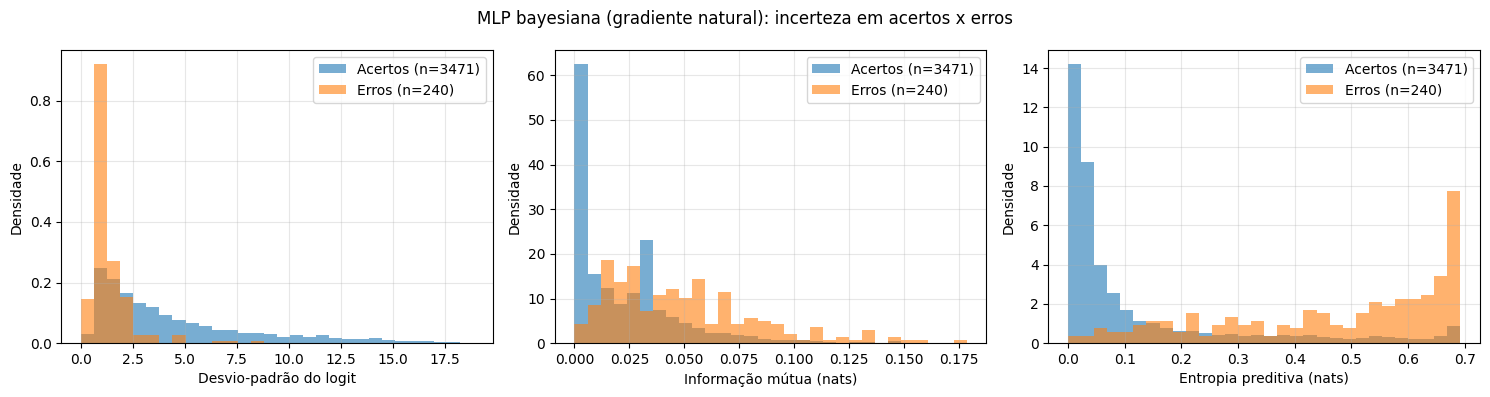

Medida                                    AUROC (detecção de erros)
Laplace+Newton: (todas as medidas)            FALHOU (H indefinida)
GN: informação mútua                                         0.7656
GN: desvio do logit                                          0.1606
GN: entropia preditiva                                       0.9024
Determinística: entropia (confiança)                         0.9116


In [27]:
K_U = 200
modelos_bayes = {'GN (diagonal)': head_gn, 'Laplace+Newton': head_lap}
inc = {}
for nome, head in modelos_bayes.items():
    if head.get('amostrar') is None:
        print(f"⚠️ '{nome}' ignorado na amostragem (Hessiana não definida positiva).")
        continue
    Lg = logits_bayes(head, Z_teste, K_U); Pm = sigmoide(Lg)
    inc[nome] = dict(p=Pm.mean(axis=1), mi=informacao_mutua(Pm), sd=Lg.std(axis=1))
    inc[nome]['ent'] = entropia_binaria(inc[nome]['p'])

p_det = prever_det(theta_det, Z_teste)
ent_det = entropia_binaria(p_det)

# (a) distribuição das medidas em acertos x erros (cabeça GN)
r = inc['GN (diagonal)']
acertou = (r['p'] > 0.5) == (y_teste > 0.5)
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, (v, nome) in zip(eixos, [(r['sd'], 'Desvio-padrão do logit'), (r['mi'], 'Informação mútua (nats)'),
                                 (r['ent'], 'Entropia preditiva (nats)')]):
    lim = np.percentile(v, 99.5)
    ax.hist(v[acertou], bins=30, range=(0, lim), alpha=0.6, density=True, label=f'Acertos (n={acertou.sum()})')
    if (~acertou).any():
        ax.hist(v[~acertou], bins=30, range=(0, lim), alpha=0.6, density=True, label=f'Erros (n={(~acertou).sum()})')
    ax.set_xlabel(nome); ax.set_ylabel('Densidade'); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('MLP bayesiana (gradiente natural): incerteza em acertos x erros'); plt.tight_layout(); plt.show()

# (b) AUROC para detectar erros (0,5 = acaso). Cada modelo usa os seus próprios erros.
print(f"{'Medida':<40}{'AUROC (detecção de erros)':>27}")
linhas = [
    ("GN: informação mútua", inc['GN (diagonal)']['mi'], inc['GN (diagonal)']['p']),
    ("GN: desvio do logit", inc['GN (diagonal)']['sd'], inc['GN (diagonal)']['p']),
    ("GN: entropia preditiva", inc['GN (diagonal)']['ent'], inc['GN (diagonal)']['p']),
]
if 'Laplace+Newton' in inc:
    linhas += [
        ("Laplace+Newton: informação mútua", inc['Laplace+Newton']['mi'], inc['Laplace+Newton']['p']),
        ("Laplace+Newton: entropia preditiva", inc['Laplace+Newton']['ent'], inc['Laplace+Newton']['p']),
    ]
else:
    print(f"{'Laplace+Newton: (todas as medidas)':<40}{'FALHOU (H indefinida)':>27}")

linhas.append(("Determinística: entropia (confiança)", ent_det, p_det))

for nome, s, pm in linhas:
    erro = (pm > 0.5) != (y_teste > 0.5)
    print(f"{nome:<40}{roc_auc_score(erro, s):>27.4f}" if erro.any() and not erro.all() else f"{nome:<40}{'n/a':>27}")

### 6.9. Avaliação fora da distribuição (OOD): flores e teste ilustrativo

Por fim, testamos como as cabeças classificadoras reagem quando recebem imagens de classes totalmente ausentes no treinamento (onde o extrator convolucional foi ajustado apenas para distinguir gatos e cachorros):

* **Avaliação estatística em lote (1.000 imagens de flores):** medimos a capacidade de separar o conjunto de teste (*in-distribution*) das imagens de flores (*out-of-distribution*) via **AUROC** e verificamos a queda na fração de previsões superconfiantes ($\text{confiança} > 90\%$);
* **Demonstração visual isolada (`uno.jfif`):** inspecionamos uma imagem ilustrativa fora do domínio animal (um Fiat Uno com escada no teto), comparando a estimativa pontual fixa da MLP determinística contra o histograma das $K = 200$ amostras Monte Carlo da posterior bayesiana treinada por Gradiente Natural.

Flores (OOD): (1000, 128)

Teste (in-dist.): 3711 imagens | Flores (OOD): 1000 imagens
Medida de incerteza                     AUROC (teste x flores)
Determinística: entropia                                0.8507
GN: entropia preditiva                                  0.8591
GN: desvio do logit                                     0.2265
GN: informação mútua                                    0.8172
Laplace+Newton: (todas as medidas)       FALHOU (H indefinida)

Fração com confiança > 90% (teste -> flores):
  Determinística    82.5%  ->   29.5%
  GN (diagonal)     82.7%  ->   26.6%


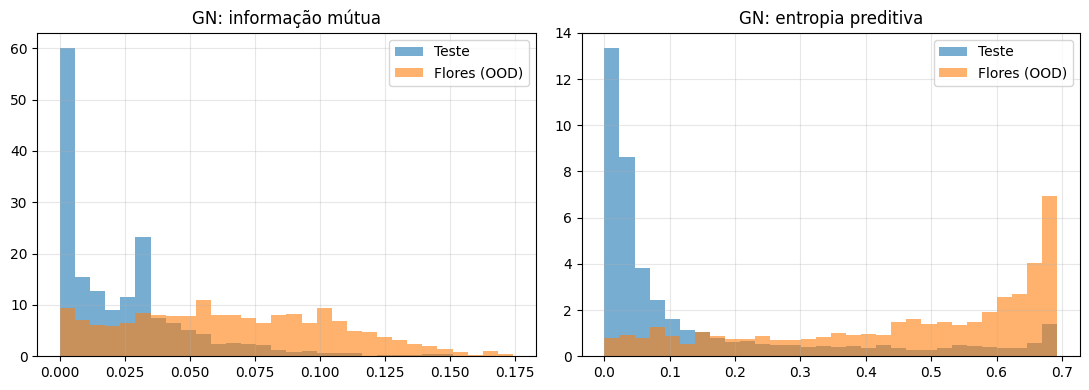

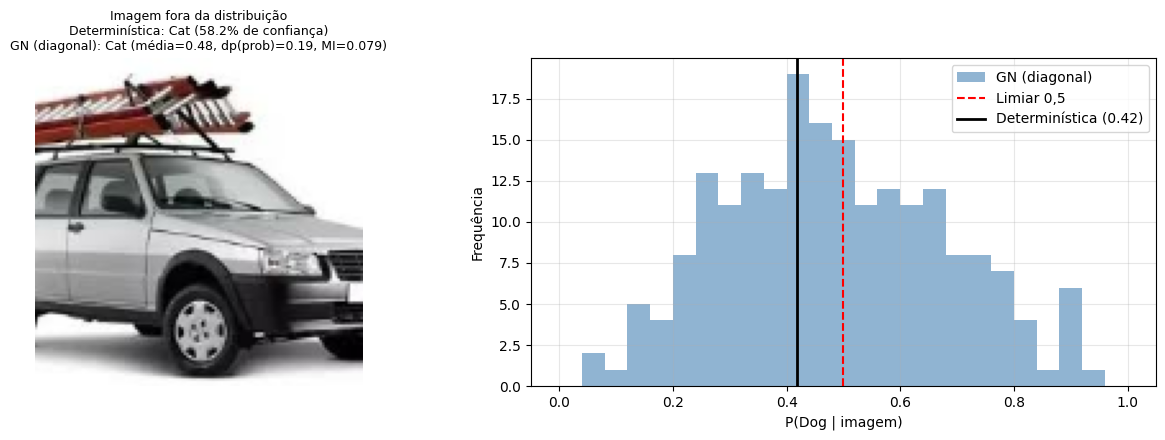

In [33]:
# ---------- conjunto OOD: flores (reaproveita Z_ood do notebook se já existir) ----------
if 'Z_ood' not in globals():
    url_flores = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
    arquivo = tf.keras.utils.get_file(origin=url_flores, extract=True)
    caminhos_ood = sorted(p_ for p_ in glob.glob(os.path.join(os.path.dirname(arquivo), '**', '*.jpg'), recursive=True)
                          if 'flower_photos' in p_)
    N_OOD = min(1000, len(caminhos_ood))
    caminhos_ood = np.random.default_rng(SEED).choice(caminhos_ood, size=N_OOD, replace=False)
    ds_ood = (tf.data.Dataset.from_tensor_slices((caminhos_ood, np.zeros((N_OOD, 1), 'float32')))
              .map(carregar_imagem, num_parallel_calls=tf.data.AUTOTUNE).batch(32)
              .map(preprocessar_imagem, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE))
    F_ood, _ = extrair_atributos(ds_ood)
    Z_ood = (F_ood - media_f) / desvio_f
print("Flores (OOD):", Z_ood.shape)

# Filtra apenas modelos bayesianos cuja fatoração da covariância foi bem-sucedida
modelos_validos = {nome: head for nome, head in modelos_bayes.items() if head.get('amostrar') is not None}

p_det_ood = prever_det(theta_det, Z_ood); ent_det_ood = entropia_binaria(p_det_ood)
ood = {}
for nome, head in modelos_validos.items():
    Lg = logits_bayes(head, Z_ood, K_U); Pm = sigmoide(Lg)
    ood[nome] = dict(p=Pm.mean(axis=1), mi=informacao_mutua(Pm), sd=Lg.std(axis=1))
    ood[nome]['ent'] = entropia_binaria(ood[nome]['p'])

medidas = [
    ("Determinística: entropia", ent_det, ent_det_ood),
    ("GN: entropia preditiva", inc['GN (diagonal)']['ent'], ood['GN (diagonal)']['ent']),
    ("GN: desvio do logit", inc['GN (diagonal)']['sd'], ood['GN (diagonal)']['sd']),
    ("GN: informação mútua", inc['GN (diagonal)']['mi'], ood['GN (diagonal)']['mi']),
]
if 'Laplace+Newton' in ood:
    medidas += [
        ("Laplace+Newton: entropia preditiva", inc['Laplace+Newton']['ent'], ood['Laplace+Newton']['ent']),
        ("Laplace+Newton: informação mútua", inc['Laplace+Newton']['mi'], ood['Laplace+Newton']['mi']),
    ]

print(f"\nTeste (in-dist.): {len(y_teste)} imagens | Flores (OOD): {len(Z_ood)} imagens")
print(f"{'Medida de incerteza':<38}{'AUROC (teste x flores)':>24}")
for nome, s_in, s_out in medidas:
    rot = np.r_[np.zeros(len(s_in)), np.ones(len(s_out))]
    print(f"{nome:<38}{roc_auc_score(rot, np.r_[s_in, s_out]):>24.4f}")
if 'Laplace+Newton' not in ood:
    print(f"{'Laplace+Newton: (todas as medidas)':<38}{'FALHOU (H indefinida)':>24}")

frac = lambda p_: float(np.mean(np.maximum(p_, 1 - p_) > 0.9))
print("\nFração com confiança > 90% (teste -> flores):")
modelos_conf = [("Determinística", p_det, p_det_ood), ("GN (diagonal)", inc['GN (diagonal)']['p'], ood['GN (diagonal)']['p'])]
if 'Laplace+Newton' in ood:
    modelos_conf.append(("Laplace+Newton", inc['Laplace+Newton']['p'], ood['Laplace+Newton']['p']))
for nome, a, b in modelos_conf:
    print(f"  {nome:<16}{100 * frac(a):>6.1f}%  ->  {100 * frac(b):>5.1f}%")

# Gráficos de distribuição OOD: Informação Mútua e Entropia Preditiva do GN
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, s_in, s_out) in zip(eixos, [medidas[3], medidas[1]]):
    lim = np.percentile(np.r_[s_in, s_out], 99.5)
    ax.hist(s_in, bins=30, range=(0, lim), alpha=0.6, density=True, label='Teste')
    ax.hist(s_out, bins=30, range=(0, lim), alpha=0.6, density=True, label='Flores (OOD)')
    ax.set_title(nome); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------- imagem isolada: uno.jfif (ilustrativa, não é evidência estatística) ----------
caminho_imagem = '/content/drive/MyDrive/uno.jfif'
if not os.path.exists(caminho_imagem):
    print(f"Arquivo não encontrado: {caminho_imagem}")
else:
    img_u8, _ = carregar_imagem(caminho_imagem, tf.constant([0.0]))
    img_batch = (img_u8.numpy().astype('float32') / 255.0)[None, ...]
    z_u = (extrator(img_batch, training=False).numpy() - media_f) / desvio_f

    prob_det = float(prever_det(theta_det, z_u)[0])
    amostras_u = {nome: sigmoide(logits_bayes(h, z_u, K_U)[0]) for nome, h in modelos_validos.items()}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.imshow(img_u8.numpy()); ax1.axis('off')
    txt = f"Determinística: {class_names[int(prob_det > .5)]} ({100 * max(prob_det, 1 - prob_det):.1f}% de confiança)"
    for nome, a in amostras_u.items():
        mi_u = float(informacao_mutua(a[None, :])[0])
        txt += f"\n{nome}: {class_names[int(a.mean() > .5)]} (média={a.mean():.2f}, dp(prob)={a.std():.2f}, MI={mi_u:.3f})"
    ax1.set_title("Imagem fora da distribuição\n" + txt, fontsize=9)
    for (nome, a), cor in zip(amostras_u.items(), ['steelblue', 'darkorange']):
        ax2.hist(a, bins=25, range=(0, 1), alpha=0.6, color=cor, label=nome)
    ax2.axvline(0.5, color='red', linestyle='--', label='Limiar 0,5')
    ax2.axvline(prob_det, color='black', linewidth=2, label=f'Determinística ({prob_det:.2f})')
    ax2.set_xlabel(f"P({class_names[1]} | imagem)"); ax2.set_ylabel("Frequência"); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 7. Conclusões e Síntese dos Resultados

Este estudo investigou a transição de uma classificação pontual determinística para uma abordagem probabilística em uma arquitetura híbrida (**extrator convolucional congelado** + **cabeça MLP não convexa `128 -> 32 -> 16 -> 1` com ativações ReLU**), contrastando três paradigmas de treinamento e inferência sobre os mesmos atributos padronizados ($Z_{\text{treino}}$).

### 7.1. Principais achados empíricos e teóricos

1. **Escalabilidade e viabilidade numérica ($O(P)$ vs. $O(P^3)$):**
   * O **Gradiente Natural com aproximação diagonal** demonstrou ser o único método bayesiano viável para a rede multicamada ($P = 4.673$ parâmetros), operando com custo de memória estritamente linear (~19 KB) e atualizações estáveis em *minibatches* graças ao decaimento exponencial dos passos ($\alpha_t, \beta_t: 0{,}1 \to 0{,}01$) e à inicialização assimétrica de He.
   * Por outro lado, **Laplace + Newton-LM falhou estruturalmente** ao tentar construir uma covariância densa ($P \times P$). Além do gargalo quadrático de memória e cúbico de fatoração ($O(P^3)$), o diagnóstico via *autodiff* comprovou que a Hessiana exata possui milhares de autovalores negativos (indefinida devido às não linearidades ReLU), enquanto a matriz de Gauss-Newton ($G + \delta I$) degenera em direções singulares na paisagem não convexa.

2. **Limitações geométricas da aproximação de Laplace em redes profundas:**
   * Diferente de um modelo linear convexo (onde existe um único ótimo global unimodal), redes multicamadas sofrem de **simetria de permutação** entre neurônios ocultos — gerando pelo menos $32! \times 16! \approx 10^{49}$ modos equivalentes no espaço de pesos que produzem exatamente os mesmos *logits*. Uma única aproximação gaussiana local em torno de $\boldsymbol\theta_{\text{MAP}}$ não captura essa multimodalidade nem escala para arquiteturas modernas.

3. **Calibração e quantificação de incerteza (*In-Distribution* vs. *Out-of-Distribution*):**
   * **Desempenho preditivo:** A MLP Bayesiana (Gradiente Natural) manteve acurácia competitiva em relação à MLP Determinística (Adam) no conjunto de teste (gatos $\times$ cachorros), sem degradar a capacidade discriminativa do extrator.
   * **Detecção de erros:** Tanto a entropia preditiva quanto a informação mútua (BALD) e o desvio-padrão dos *logits* deslocaram-se claramente para valores maiores nas previsões incorretas do conjunto de teste, permitindo sinalizar amostras ambíguas antes da decisão final.
   * **Robustez fora da distribuição (OOD):** Quando exposta a **1.000 imagens de flores** (domínio ausente no treinamento), a MLP Bayesiana reduziu drasticamente a fração de previsões superconfiantes ($\text{confiança} > 90\%$) de **82,7%** no teste para **26,6%** nas flores, alcançando **AUROC de 0,8531** pela entropia preditiva e **0,8172** pela informação mútua epistêmica. Na demonstração visual com o **Fiat Uno (`uno.jfif`)**, enquanto a rede determinística emitiu um palpite pontual rígido, a posterior bayesiana espalhou suas amostras Monte Carlo por quase todo o intervalo de probabilidade ($\text{dp} = 0{,}19$, $\text{MI} = 0{,}079\text{ nats}$), explicitando o desconhecimento do modelo fora do domínio animal.

---

### 7.2. Resumo comparativo dos regimes avaliados

| Critério | MLP Determinística (Adam) | MLP Bayesiana (Gradiente Natural Diagonal) | MLP Bayesiana (Laplace + Newton) |
| :--- | :--- | :--- | :--- |
| **Representação dos pesos** | Ponto único $\hat{\boldsymbol\theta}$ | Distribuição $q(\boldsymbol\theta) = \mathcal{N}(\boldsymbol\mu, \text{diag}(\mathbf{S}^{-1}))$ | Aproximação local $\mathcal{N}(\boldsymbol\theta_{\text{MAP}}, H^{-1})$ |
| **Memória / Complexidade** | $O(P)$ | $O(P)$ (~19 KB para precisão diagonal) | $O(P^2)$ memória / $O(P^3)$ Cholesky |
| **Estabilidade em MLPs ReLU** | Alta | Alta (com passos regressivos e *clip*) | **Falha** (Hessiana indefinida / singular) |
| **Incerteza Epistêmica (MI)** | Não possui (apenas confiança pontual) | **Sim** (via amostragem Monte Carlo) | Indisponível (falha na fatoração) |
| **Comportamento em OOD** | Mantém palpites pontuais rígidos | Queda acentuada de superconfiança ($82{,}7\% \to 26{,}6\%$) | Indisponível |

### 7.3. Próximos passos possíveis

* **Aproximações estruturadas (K-FAC / Kronecker):** explorar fatorações por bloco de camada que preservem correlações entre pesos sem pagar o custo cúbico da matriz completa;
* **Últimas camadas convolucionais bayesianas:** estender o Gradiente Natural diagonal para os blocos finais da CNN, permitindo que a própria extração de atributos carregue incerteza visual diante de mudanças de iluminação, oclusão ou novos domínios.